# NOVA Skin — D2C Marketing Analytics

## Project Overview

This project analyzes the marketing performance of NOVA Skin, a fictional
direct-to-consumer skincare brand operating in India.

The analysis evaluates the effectiveness of organic social media, paid
advertising, email marketing, influencer marketing, website activity,
customer acquisition, and e-commerce performance.

## Business Objective

The primary objective is to understand how marketing activities contribute
to:

- Audience reach and engagement
- Website traffic
- Customer acquisition
- Conversion
- Revenue generation
- Customer retention
- Marketing efficiency

## Key Business Questions

1. Which marketing channels generate the most revenue?
2. Which channels have the lowest customer acquisition cost?
3. Which paid campaigns generate the highest ROAS?
4. Which organic content formats generate the highest engagement?
5. Which products generate the most revenue?
6. Where are customers dropping off in the marketing funnel?
7. How does marketing performance change over time?
8. How effective are email and influencer campaigns?
9. Does increased advertising spend translate into increased revenue?
10. Which marketing activities should the business prioritize?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Data Loading

In [2]:
files = {
    "products": "products.csv",
    "campaigns": "campaigns.csv",
    "social_posts": "social_posts.csv",
    "ad_performance": "ad_performance.csv",
    "website_traffic": "website_traffic.csv",
    "orders": "orders.csv",
    "email_campaigns": "email_campaigns.csv",
    "influencer_campaigns": "influencer_campaigns.csv"
}

data = {}

for name, file in files.items():
    data[name] = pd.read_csv(file)
    print(f"{name}: {data[name].shape}")

products: (8, 4)
campaigns: (15, 9)
social_posts: (1030, 15)
ad_performance: (1145, 12)
website_traffic: (2920, 9)
orders: (8745, 10)
email_campaigns: (52, 10)
influencer_campaigns: (8, 14)


In [3]:
products = data["products"]
campaigns = data["campaigns"]
social_posts = data["social_posts"]
ad_performance = data["ad_performance"]
website_traffic = data["website_traffic"]
orders = data["orders"]
email_campaigns = data["email_campaigns"]
influencer_campaigns = data["influencer_campaigns"]

In [4]:
orders.head()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,revenue,acquisition_channel,campaign_id
0,ORD000001,2025-12-26,CUST00001,P002,1,799,0.00,799.00,Email,NaN
1,ORD000002,2025-12-28,CUST00002,P006,2,649,64.90,"1,233.10",Organic Search,NaN
2,ORD000003,2025-12-31,CUST00003,P008,1,1999,199.90,"1,799.10",Paid Social,C015
3,ORD000004,2025-12-22,CUST00004,P001,1,899,89.90,809.10,Influencer,NaN
4,ORD000005,2025-11-11,CUST00005,P002,1,799,119.85,679.15,Influencer,NaN


## 2. Data Quality Assessment

Before performing exploratory analysis, the datasets are assessed for:

- Missing values
- Duplicate records
- Data types
- Date consistency
- Invalid numerical values
- Primary-key uniqueness
- Referential integrity

In [5]:
for name, df in data.items():
    print(f"\n{name.upper()}")
    print("-" * 50)
    print(f"Rows: {df.shape[0]:,}")
    print(f"Columns: {df.shape[1]}")
    print(df.dtypes)


PRODUCTS
--------------------------------------------------
Rows: 8
Columns: 4
product_id      object
product_name    object
category        object
price            int64
dtype: object

CAMPAIGNS
--------------------------------------------------
Rows: 15
Columns: 9
campaign_id        object
campaign_name      object
platform           object
campaign_type      object
product_id         object
start_date         object
end_date           object
planned_budget      int64
actual_spend      float64
dtype: object

SOCIAL_POSTS
--------------------------------------------------
Rows: 1,030
Columns: 15
post_id             object
post_date           object
platform            object
content_type        object
content_topic       object
product_id          object
reach                int64
impressions          int64
likes                int64
comments             int64
shares               int64
saves                int64
video_views          int64
link_clicks          int64
followers_gained 

In [6]:
missing_summary = []

for name, df in data.items():
    for column in df.columns:
        missing_count = df[column].isna().sum()
        missing_pct = (missing_count / len(df)) * 100

        missing_summary.append({
            "dataset": name,
            "column": column,
            "missing_count": missing_count,
            "missing_percentage": missing_pct
        })

missing_df = pd.DataFrame(missing_summary)

missing_df[missing_df["missing_count"] > 0].sort_values(
    "missing_percentage",
    ascending=False
)

,dataset,column,missing_count,missing_percentage
58,orders,campaign_id,5424,62.02
18,social_posts,product_id,368,35.73
8,campaigns,product_id,4,26.67


In [7]:
duplicate_summary = []

for name, df in data.items():
    duplicate_summary.append({
        "dataset": name,
        "duplicate_rows": df.duplicated().sum()
    })

duplicates_df = pd.DataFrame(duplicate_summary)

duplicates_df

,dataset,duplicate_rows
0,products,0
1,campaigns,0
2,social_posts,0
3,ad_performance,0
4,website_traffic,0
5,orders,0
6,email_campaigns,0
7,influencer_campaigns,0


In [8]:
primary_keys = {
    "products": "product_id",
    "campaigns": "campaign_id",
    "social_posts": "post_id",
    "email_campaigns": "email_id",
    "influencer_campaigns": "campaign_id",
    "orders": "order_id",
}

for dataset, key in primary_keys.items():
    df = data[dataset]

    duplicate_keys = df[key].duplicated().sum()
    null_keys = df[key].isna().sum()

    print(
        f"{dataset:25} | "
        f"Duplicate {key}: {duplicate_keys:4} | "
        f"Null {key}: {null_keys:4}"
    )

products                  | Duplicate product_id:    0 | Null product_id:    0
campaigns                 | Duplicate campaign_id:    0 | Null campaign_id:    0
social_posts              | Duplicate post_id:    0 | Null post_id:    0
email_campaigns           | Duplicate email_id:    0 | Null email_id:    0
influencer_campaigns      | Duplicate campaign_id:    0 | Null campaign_id:    0
orders                    | Duplicate order_id:    0 | Null order_id:    0


In [9]:
date_columns = {
    "campaigns": ["start_date", "end_date"],
    "social_posts": ["post_date"],
    "ad_performance": ["date"],
    "website_traffic": ["date"],
    "orders": ["order_date"],
    "email_campaigns": ["send_date"],
    "influencer_campaigns": ["campaign_date"]
}

for dataset, columns in date_columns.items():
    print(f"\n{dataset.upper()}")

    for column in columns:
        data[dataset][column] = pd.to_datetime(
            data[dataset][column],
            errors="coerce"
        )

        print(
            f"{column}: "
            f"{data[dataset][column].min().date()} → "
            f"{data[dataset][column].max().date()}"
        )


CAMPAIGNS
start_date: 2025-01-01 → 2025-12-01
end_date: 2025-01-20 → 2025-12-31

SOCIAL_POSTS
post_date: 2025-01-01 → 2025-12-31

AD_PERFORMANCE
date: 2025-01-01 → 2025-12-31

WEBSITE_TRAFFIC
date: 2025-01-01 → 2025-12-31

ORDERS
order_date: 2025-01-06 → 2025-12-31

EMAIL_CAMPAIGNS
send_date: 2025-01-03 → 2025-12-26

INFLUENCER_CAMPAIGNS
campaign_date: 2025-01-06 → 2025-11-10


In [10]:
numeric_checks = {
    "social_posts": [
        "reach", "impressions", "likes", "comments",
        "shares", "saves", "video_views",
        "link_clicks", "followers_gained"
    ],

    "ad_performance": [
        "impressions", "reach", "clicks", "spend",
        "landing_page_views", "add_to_cart",
        "purchases", "revenue"
    ],

    "website_traffic": [
        "sessions", "new_users", "product_views",
        "add_to_cart", "checkout_started",
        "purchases", "revenue"
    ],

    "orders": [
        "quantity", "unit_price", "discount", "revenue"
    ]
}

for dataset, columns in numeric_checks.items():
    df = data[dataset]

    print(f"\n{dataset.upper()}")

    for column in columns:
        negative_count = (df[column] < 0).sum()

        if negative_count > 0:
            print(f"{column}: {negative_count} negative values")


SOCIAL_POSTS

AD_PERFORMANCE

WEBSITE_TRAFFIC

ORDERS


In [11]:
print("Clicks > impressions:",
      (ad_performance["clicks"] > ad_performance["impressions"]).sum())

print("Reach > impressions:",
      (ad_performance["reach"] > ad_performance["impressions"]).sum())

print("Landing page views > clicks:",
      (ad_performance["landing_page_views"] > ad_performance["clicks"]).sum())

print("Add to cart > landing page views:",
      (ad_performance["add_to_cart"] > ad_performance["landing_page_views"]).sum())

print("Purchases > add to cart:",
      (ad_performance["purchases"] > ad_performance["add_to_cart"]).sum())

Clicks > impressions: 0
Reach > impressions: 0
Landing page views > clicks: 0
Add to cart > landing page views: 0
Purchases > add to cart: 0


In [12]:
print("Product views < sessions:",
      (website_traffic["product_views"] < website_traffic["sessions"]).sum())

print("Add to cart > product views:",
      (website_traffic["add_to_cart"] > website_traffic["product_views"]).sum())

print("Checkout > add to cart:",
      (website_traffic["checkout_started"] > website_traffic["add_to_cart"]).sum())

print("Purchases > checkout:",
      (website_traffic["purchases"] > website_traffic["checkout_started"]).sum())

Product views < sessions: 0
Add to cart > product views: 0
Checkout > add to cart: 0
Purchases > checkout: 0


In [13]:
invalid_products = ~orders["product_id"].isin(products["product_id"])

print(
    "Orders with invalid product_id:",
    invalid_products.sum()
)

Orders with invalid product_id: 0


In [14]:
invalid_campaigns = ~ad_performance["campaign_id"].isin(
    campaigns["campaign_id"]
)

print(
    "Ad performance rows with invalid campaign_id:",
    invalid_campaigns.sum()
)

Ad performance rows with invalid campaign_id: 0


In [15]:
orders_with_campaign = orders[
    orders["campaign_id"].notna()
]

invalid_order_campaigns = ~orders_with_campaign["campaign_id"].isin(
    campaigns["campaign_id"]
)

print(
    "Orders with invalid campaign_id:",
    invalid_order_campaigns.sum()
)

Orders with invalid campaign_id: 0


## 3. Data Quality Findings

The initial data-quality assessment identified the following:

### Missing Values

Missing values were present in three fields:

- `orders.campaign_id`
- `social_posts.product_id`
- `campaigns.product_id`

These missing values were retained because they have valid business interpretations.

Not every order can be attributed to a specific paid campaign, and not every
social-media post or marketing campaign is associated with a single product.

### Duplicate Records

No duplicate records were identified across the datasets.

### Primary Keys

All tested primary-key fields were unique and contained no null values.

### Date Validation

All operational datasets fall within the intended 2025 analysis period.

### Logical Consistency

Marketing funnel metrics passed logical consistency checks. For example:

- Clicks do not exceed impressions.
- Add-to-cart events do not exceed landing-page views.
- Purchases do not exceed add-to-cart events.
- Website purchases do not exceed checkout starts.

### Referential Integrity

Product and campaign relationships were validated successfully with no invalid
foreign-key references identified.

### Data Cleaning Decision

No rows were removed during the initial cleaning stage.

Missing values with valid business meaning were retained rather than imputed or
removed.


## 4. Customer Data Preparation

Create a customer-level dataset from the existing order transactions.
The dataset will contain each customer's first purchase date,
acquisition channel, purchase history, and customer segment.


In [16]:

# Ensure order dates are in datetime format
orders["order_date"] = pd.to_datetime(orders["order_date"])

# Create one record per customer
customers = (
    orders.groupby("customer_id")
    .agg(
        first_purchase_date=("order_date", "min"),
        last_purchase_date=("order_date", "max"),
        total_orders=("order_id", "nunique"),
        total_revenue=("revenue", "sum"),
        acquisition_channel=("acquisition_channel", "first")
    )
    .reset_index()
)

# Segment customers by purchase frequency
customers["customer_segment"] = np.select(
    [
        customers["total_orders"] == 1,
        customers["total_orders"].between(2, 3),
        customers["total_orders"] >= 4
    ],
    [
        "One-Time",
        "Repeat",
        "Loyal"
    ],
    default="Unclassified"
)

# Save the customer dataset
customers.to_csv("customers.csv", index=False)

# Preview the result
print("Customer dataset created successfully.")
print("Shape:", customers.shape)

display(customers.head())


Customer dataset created successfully.
Shape: (5200, 7)


,customer_id,first_purchase_date,last_purchase_date,total_orders,total_revenue,acquisition_channel,customer_segment
0,CUST00001,2025-12-26,2025-12-26,1,799.00,Email,One-Time
1,CUST00002,2025-12-28,2025-12-28,1,"1,233.10",Organic Search,One-Time
2,CUST00003,2025-12-31,2025-12-31,1,"1,799.10",Paid Social,One-Time
3,CUST00004,2025-12-22,2025-12-22,1,809.10,Influencer,One-Time
4,CUST00005,2025-11-11,2025-11-11,1,679.15,Influencer,One-Time


In [17]:

print("Duplicate customer IDs:",
      customers["customer_id"].duplicated().sum())

print("Missing customer IDs:",
      customers["customer_id"].isna().sum())

print("Missing first purchase dates:",
      customers["first_purchase_date"].isna().sum())

print("\nCustomer segment distribution:")

segment_summary = (
    customers.groupby("customer_segment")
    .agg(
        customers=("customer_id", "nunique"),
        revenue=("total_revenue", "sum"),
        avg_revenue_per_customer=("total_revenue", "mean")
    )
    .sort_values("customers", ascending=False)
    .round(2)
)

display(segment_summary)


Duplicate customer IDs: 0
Missing customer IDs: 0
Missing first purchase dates: 0

Customer segment distribution:


,customers,revenue,avg_revenue_per_customer
customer_segment,,,
One-Time,3024,"2,755,627.50",911.25
Repeat,1829,"3,793,439.70","2,074.05"
Loyal,347,"1,358,992.10","3,916.40"


In [18]:

# Overall business performance

total_orders = orders["order_id"].nunique()
total_customers = orders["customer_id"].nunique()
total_revenue = orders["revenue"].sum()
average_order_value = total_revenue / total_orders

total_ad_spend = ad_performance["spend"].sum()

print("NOVA SKIN — BUSINESS OVERVIEW")
print("-" * 40)
print(f"Total Orders: {total_orders:,}")
print(f"Unique Purchasing Customers: {total_customers:,}")
print(f"Total Order Revenue: ₹{total_revenue:,.2f}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")
print(f"Paid Advertising Spend: ₹{total_ad_spend:,.2f}")


NOVA SKIN — BUSINESS OVERVIEW
----------------------------------------
Total Orders: 8,745
Unique Purchasing Customers: 5,200
Total Order Revenue: ₹7,908,059.30
Average Order Value: ₹904.29
Paid Advertising Spend: ₹2,404,606.80


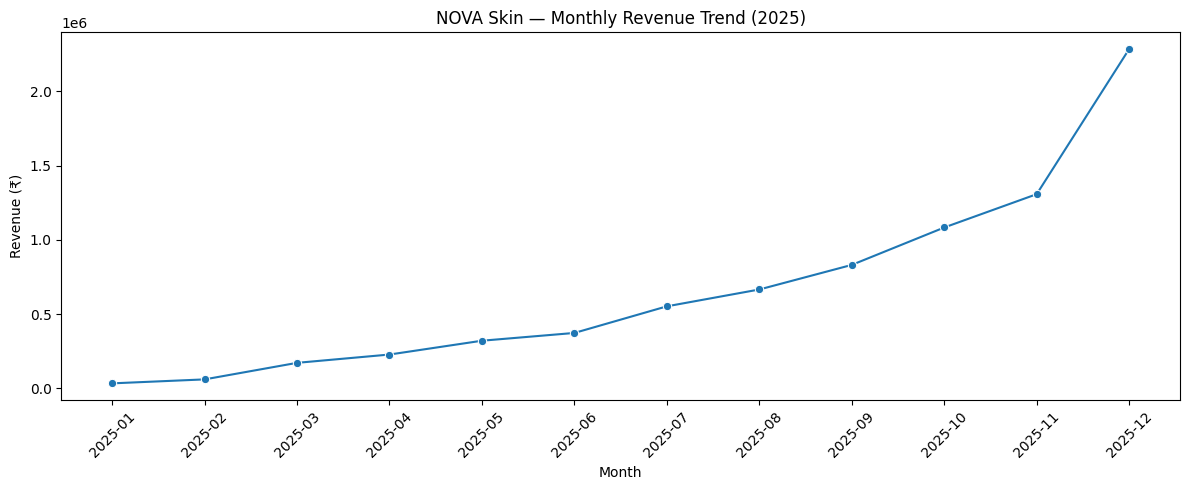

,month,revenue,orders
0,2025-01,"33,437.45",40
1,2025-02,"60,146.40",62
2,2025-03,"171,555.70",201
3,2025-04,"227,478.50",234
4,2025-05,"320,511.80",353
5,2025-06,"372,829.05",407
6,2025-07,"552,042.45",605
7,2025-08,"665,399.50",722
8,2025-09,"830,868.20",912
9,2025-10,"1,082,728.80",1183


In [19]:

# Ensure dates are in datetime format
orders["order_date"] = pd.to_datetime(orders["order_date"])

# Aggregate monthly revenue
monthly_revenue = (
    orders.assign(month=orders["order_date"].dt.to_period("M"))
    .groupby("month", as_index=False)
    .agg(
        revenue=("revenue", "sum"),
        orders=("order_id", "nunique")
    )
)

monthly_revenue["month"] = monthly_revenue["month"].astype(str)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_revenue,
    x="month",
    y="revenue",
    marker="o"
)

plt.title("NOVA Skin — Monthly Revenue Trend (2025)")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_revenue.round(2))



### Monthly Revenue Analysis — Key Findings

1. Revenue generally increases over the analysis period, with some monthly fluctuations.
2. September and October show stronger revenue performance than the preceding summer months.
3. November records the highest monthly revenue, aligning with the synthetic dataset's seasonal campaign assumptions.
4. December revenue declines compared with November.
5. Further analysis is required to determine how order volume, average order value, marketing expenditure, and campaign performance contribute to these changes.

**Business implication:** Marketing investment and campaign performance should be evaluated alongside revenue before allocating future budgets.


In [20]:

# Correct synthetic order-date distribution
# Preserve transaction values; reassign dates to remove the late-year bias.

rng = np.random.default_rng(2025)

orders = orders.copy()
orders["order_date"] = pd.to_datetime(orders["order_date"])
campaigns["start_date"] = pd.to_datetime(campaigns["start_date"])
campaigns["end_date"] = pd.to_datetime(campaigns["end_date"])

all_dates = pd.date_range("2025-01-01", "2025-12-31", freq="D")

# Illustrative seasonality assumptions for a fictional D2C brand.
monthly_weights = {
    1: 1.00, 2: 1.20, 3: 1.15, 4: 1.12,
    5: 1.12, 6: 1.00, 7: 1.08, 8: 1.08,
    9: 1.20, 10: 1.30, 11: 1.55, 12: 1.25
}

date_weights = np.array(
    [monthly_weights[d.month] for d in all_dates],
    dtype=float
)
date_probabilities = date_weights / date_weights.sum()

# Preserve each customer's number of orders.
# Assign dates and sort them chronologically within each customer.
for customer_id, idx in orders.groupby("customer_id").groups.items():
    sampled_dates = rng.choice(
        all_dates.to_numpy(),
        size=len(idx),
        replace=True,
        p=date_probabilities
    )

    orders.loc[idx, "order_date"] = sorted(sampled_dates)

orders["order_date"] = pd.to_datetime(orders["order_date"])

# Reassign paid campaign IDs to campaigns active on each new order date.
orders["campaign_id"] = None

for idx, row in orders.iterrows():
    if row["acquisition_channel"] == "Paid Social":
        platform = "Meta Ads"
    elif row["acquisition_channel"] == "Paid Search":
        platform = "Google Ads"
    else:
        continue

    eligible = campaigns[
        (campaigns["platform"] == platform)
        & (campaigns["start_date"] <= row["order_date"])
        & (campaigns["end_date"] >= row["order_date"])
    ]

    if not eligible.empty:
        orders.at[idx, "campaign_id"] = rng.choice(
            eligible["campaign_id"].to_numpy()
        )

print("Corrected order dates and campaign assignments.")
print("Orders:", orders["order_id"].nunique())
print("Revenue preserved:", round(orders["revenue"].sum(), 2))


Corrected order dates and campaign assignments.
Orders: 8745
Revenue preserved: 7908059.3


In [21]:
orders.to_csv("orders.csv", index=False)


### Monthly Revenue Analysis — Key Findings

1. Revenue generally increases over the analysis period, with some monthly fluctuations.
2. September and October show stronger revenue performance than the preceding summer months.
3. November records the highest monthly revenue, aligning with the synthetic dataset's seasonal campaign assumptions.
4. December revenue declines compared with November.
5. Further analysis is required to determine how order volume, average order value, marketing expenditure, and campaign performance contribute to these changes.

**Business implication:** Marketing investment and campaign performance should be evaluated alongside revenue before allocating future budgets.



## 6. Organic Social Media Analysis

This section evaluates organic social media performance across Instagram,
Facebook, and YouTube. The analysis compares reach, impressions, engagement,
content formats, content topics, and link clicks.


In [22]:

# Inspect organic social media data

print("Dataset shape:", social_posts.shape)
print("\nPlatforms:")
print(social_posts["platform"].value_counts())

print("\nContent formats:")
print(social_posts["content_type"].value_counts())

print("\nContent topics:")
print(social_posts["content_topic"].value_counts())

display(social_posts.head())


Dataset shape: (1030, 15)

Platforms:
platform
Instagram    512
Facebook     262
YouTube      256
Name: count, dtype: int64

Content formats:
content_type
Reel                 224
Static               220
Carousel             197
Short                142
Story                133
Educational Video    114
Name: count, dtype: int64

Content topics:
content_topic
Skincare Tips           234
Product Education       187
Ingredient Education    156
Promotion               147
Lifestyle               118
Customer Story          102
Founder Story            86
Name: count, dtype: int64


,post_id,post_date,platform,content_type,content_topic,product_id,reach,impressions,likes,comments,shares,saves,video_views,link_clicks,followers_gained
0,POST00001,2025-01-01,Instagram,Carousel,Promotion,P007,4025,6160,99,11,18,33,0,95,20
1,POST00002,2025-01-01,Instagram,Carousel,Ingredient Education,P002,6485,9505,178,28,48,50,0,62,21
2,POST00003,2025-01-01,Instagram,Static,Promotion,NaN,3598,4723,64,5,7,13,0,48,15
3,POST00004,2025-01-02,YouTube,Short,Promotion,P007,9655,12973,405,29,51,49,7969,233,43
4,POST00005,2025-01-02,YouTube,Educational Video,Ingredient Education,P001,9957,14778,428,56,90,97,7425,117,11


In [23]:

# Create a working copy
social_analysis = social_posts.copy()

# Calculate total interactions
social_analysis["total_engagements"] = (
    social_analysis["likes"]
    + social_analysis["comments"]
    + social_analysis["shares"]
    + social_analysis["saves"]
)

# Engagement rate based on reach
social_analysis["engagement_rate"] = np.where(
    social_analysis["reach"] > 0,
    social_analysis["total_engagements"]
    / social_analysis["reach"] * 100,
    0
)

# Click-through rate based on impressions
social_analysis["social_ctr"] = np.where(
    social_analysis["impressions"] > 0,
    social_analysis["link_clicks"]
    / social_analysis["impressions"] * 100,
    0
)

display(
    social_analysis[
        [
            "post_id", "platform", "content_type",
            "reach", "impressions", "total_engagements",
            "engagement_rate", "link_clicks", "social_ctr"
        ]
    ].head()
)


,post_id,platform,content_type,reach,impressions,total_engagements,engagement_rate,link_clicks,social_ctr
0,POST00001,Instagram,Carousel,4025,6160,161,4.00,95,1.54
1,POST00002,Instagram,Carousel,6485,9505,304,4.69,62,0.65
2,POST00003,Instagram,Static,3598,4723,89,2.47,48,1.02
3,POST00004,YouTube,Short,9655,12973,534,5.53,233,1.80
4,POST00005,YouTube,Educational Video,9957,14778,671,6.74,117,0.79


In [24]:

# Platform-level performance analysis

platform_performance = (
    social_analysis.groupby("platform")
    .agg(
        total_posts=("post_id", "nunique"),
        total_reach=("reach", "sum"),
        total_impressions=("impressions", "sum"),
        total_engagements=("total_engagements", "sum"),
        total_link_clicks=("link_clicks", "sum"),
        avg_reach_per_post=("reach", "mean"),
        avg_engagement_rate=("engagement_rate", "mean"),
        avg_ctr=("social_ctr", "mean")
    )
    .reset_index()
)

platform_performance["engagement_rate_pct"] = (
    platform_performance["total_engagements"]
    / platform_performance["total_reach"] * 100
)

platform_performance["ctr_pct"] = (
    platform_performance["total_link_clicks"]
    / platform_performance["total_impressions"] * 100
)

platform_performance = platform_performance.round(2)

display(
    platform_performance.sort_values(
        "engagement_rate_pct", ascending=False
    )
)


,platform,total_posts,total_reach,total_impressions,total_engagements,total_link_clicks,avg_reach_per_post,avg_engagement_rate,avg_ctr,engagement_rate_pct,ctr_pct
2,YouTube,256,2477170,3534303,130609,36533,"9,676.45",5.55,1.11,5.27,1.03
1,Instagram,512,2783954,3906697,113708,44017,"5,437.41",3.92,1.14,4.08,1.13
0,Facebook,262,1140348,1613211,29985,17587,"4,352.47",2.59,1.15,2.63,1.09


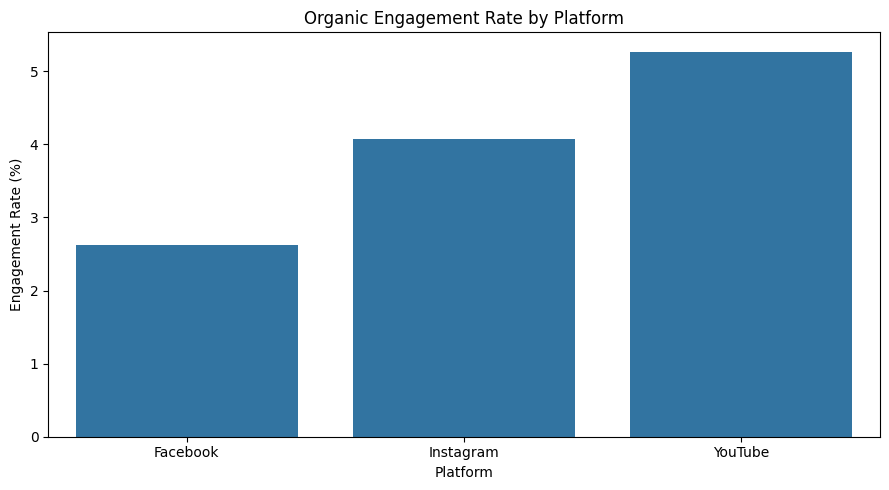

In [25]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=platform_performance,
    x="platform",
    y="engagement_rate_pct"
)

plt.title("Organic Engagement Rate by Platform")
plt.xlabel("Platform")
plt.ylabel("Engagement Rate (%)")
plt.tight_layout()
plt.show()


In [26]:

content_performance = (
    social_analysis.groupby("content_type")
    .agg(
        total_posts=("post_id", "nunique"),
        avg_reach=("reach", "mean"),
        avg_engagements=("total_engagements", "mean"),
        avg_engagement_rate=("engagement_rate", "mean"),
        total_link_clicks=("link_clicks", "sum")
    )
    .reset_index()
    .sort_values("avg_engagement_rate", ascending=False)
    .round(2)
)

display(content_performance)


,content_type,total_posts,avg_reach,avg_engagements,avg_engagement_rate,total_link_clicks
3,Short,142,"10,414.15",570.56,5.75,22810
1,Educational Video,114,"8,757.55",435.00,5.30,13723
2,Reel,224,"7,046.76",285.06,3.95,25287
0,Carousel,197,"5,289.44",212.65,3.79,17229
5,Story,133,"3,030.07",88.26,3.04,5979
4,Static,220,"4,094.59",119.13,2.95,13109


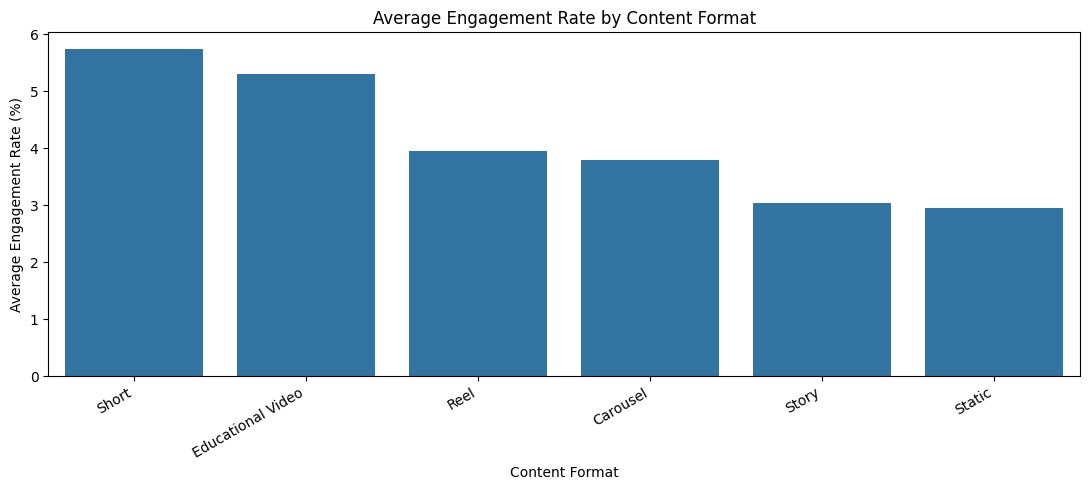

In [27]:

plt.figure(figsize=(11, 5))

sns.barplot(
    data=content_performance,
    x="content_type",
    y="avg_engagement_rate"
)

plt.title("Average Engagement Rate by Content Format")
plt.xlabel("Content Format")
plt.ylabel("Average Engagement Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [28]:

top_posts = (
    social_analysis.nlargest(10, "engagement_rate")[
        [
            "post_id",
            "post_date",
            "platform",
            "content_type",
            "content_topic",
            "reach",
            "total_engagements",
            "engagement_rate",
            "link_clicks"
        ]
    ]
)

display(top_posts)


,post_id,post_date,platform,content_type,content_topic,reach,total_engagements,engagement_rate,link_clicks
687,POST00688,2025-08-28,YouTube,Short,Product Education,12313,1068,8.67,250
642,POST00643,2025-08-12,YouTube,Short,Product Education,7526,650,8.64,168
124,POST00125,2025-02-13,YouTube,Short,Lifestyle,6316,545,8.63,132
533,POST00534,2025-07-05,YouTube,Educational Video,Skincare Tips,6584,567,8.61,80
176,POST00177,2025-03-01,YouTube,Short,Skincare Tips,13381,1105,8.26,140
63,POST00064,2025-01-23,YouTube,Short,Promotion,15135,1247,8.24,345
136,POST00137,2025-02-18,YouTube,Short,Skincare Tips,6483,531,8.19,78
429,POST00430,2025-05-31,YouTube,Short,Product Education,10167,819,8.06,211
191,POST00192,2025-03-08,YouTube,Short,Founder Story,7016,562,8.01,72
676,POST00677,2025-08-25,YouTube,Short,Customer Story,12568,1005,8.00,191


## 6.4 Content Topic Performance Analysis

Evaluate organic social media performance across different content topics
to identify which subjects generate the highest audience engagement,
reach, and website traffic.

In [29]:

# Topic-level performance

topic_performance = (
    social_analysis.groupby("content_topic")
    .agg(
        total_posts=("post_id", "nunique"),
        total_reach=("reach", "sum"),
        avg_reach=("reach", "mean"),
        total_engagements=("total_engagements", "sum"),
        avg_engagement_rate=("engagement_rate", "mean"),
        total_link_clicks=("link_clicks", "sum"),
        total_impressions=("impressions", "sum")
    )
    .reset_index()
)

topic_performance["weighted_engagement_rate"] = (
    topic_performance["total_engagements"]
    / topic_performance["total_reach"] * 100
)

topic_performance["ctr"] = (
    topic_performance["total_link_clicks"]
    / topic_performance["total_impressions"] * 100
)

topic_performance = topic_performance.sort_values(
    "avg_engagement_rate",
    ascending=False
).round(2)

display(topic_performance)


,content_topic,total_posts,total_reach,avg_reach,total_engagements,avg_engagement_rate,total_link_clicks,total_impressions,weighted_engagement_rate,ctr
3,Lifestyle,118,672787,"5,701.58",30640,4.22,9962,956905,4.55,1.04
4,Product Education,187,1135275,"6,070.99",50585,4.10,16734,1615725,4.46,1.04
1,Founder Story,86,441922,"5,138.63",19513,4.00,7064,619044,4.42,1.14
2,Ingredient Education,156,924955,"5,929.20",41624,3.97,14245,1266826,4.50,1.12
5,Promotion,147,1047573,"7,126.35",41577,3.91,19092,1521842,3.97,1.25
6,Skincare Tips,234,1458120,"6,231.28",62050,3.91,21362,2052225,4.26,1.04
0,Customer Story,102,720840,"7,067.06",28313,3.83,9678,1021644,3.93,0.95


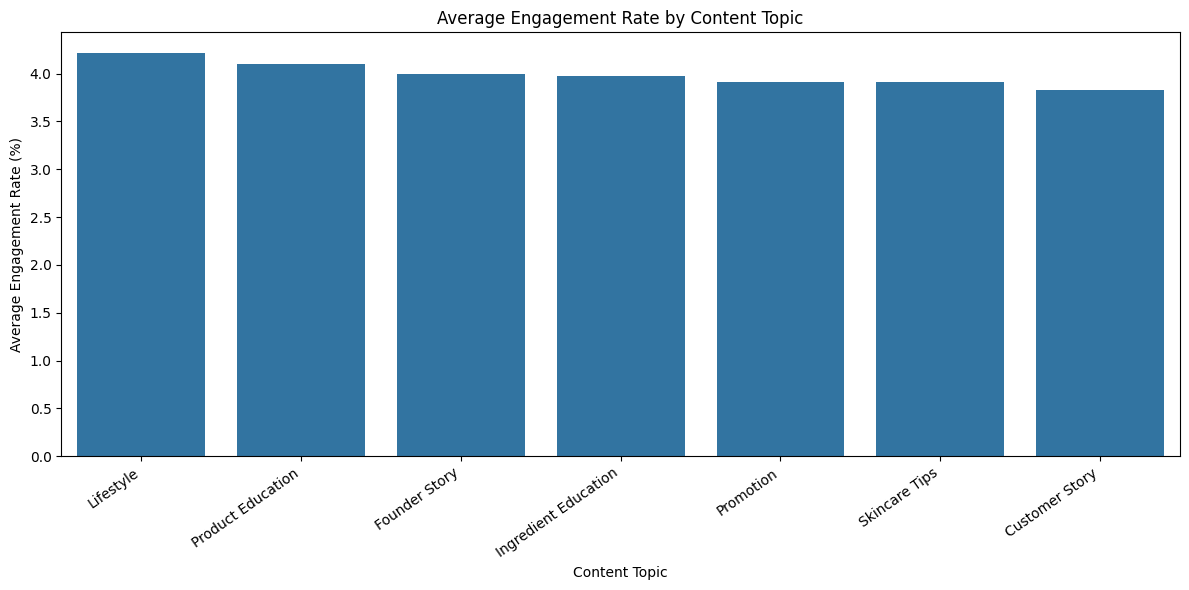

In [30]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=topic_performance.sort_values(
        "avg_engagement_rate",
        ascending=False
    ),
    x="content_topic",
    y="avg_engagement_rate"
)

plt.title("Average Engagement Rate by Content Topic")
plt.xlabel("Content Topic")
plt.ylabel("Average Engagement Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


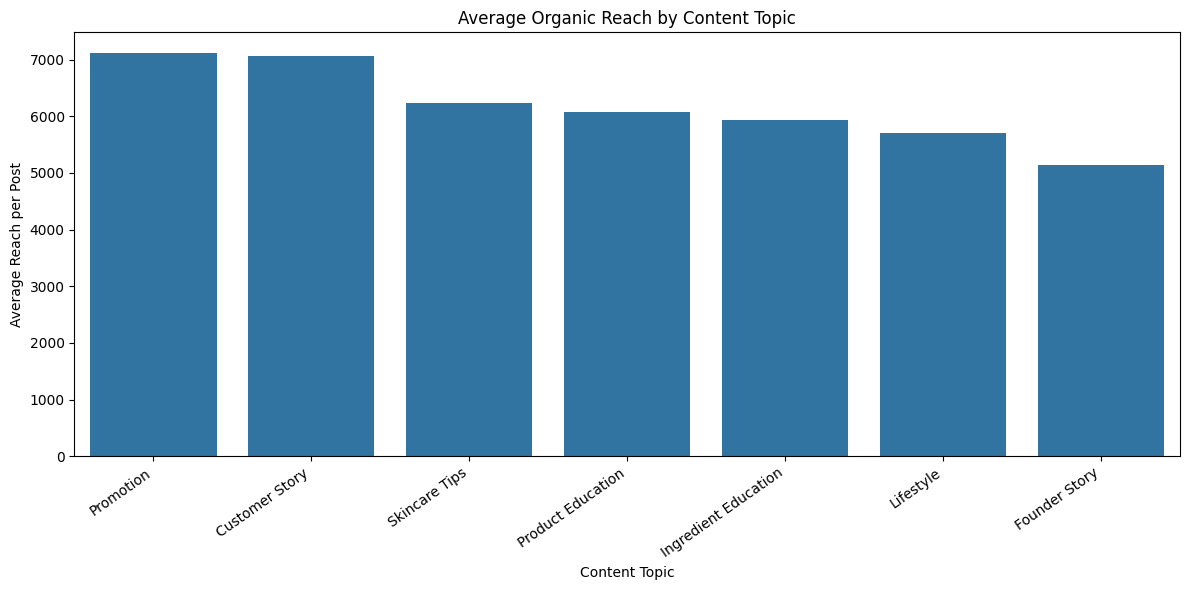

In [31]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=topic_performance.sort_values(
        "avg_reach",
        ascending=False
    ),
    x="content_topic",
    y="avg_reach"
)

plt.title("Average Organic Reach by Content Topic")
plt.xlabel("Content Topic")
plt.ylabel("Average Reach per Post")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


### 6.5 Monthly Organic Social Media Performance

Analyze monthly trends in organic reach, impressions, engagements,
engagement rate, and link clicks to identify seasonal patterns
and changes in social media performance.

In [32]:

# Convert post date
social_analysis["post_date"] = pd.to_datetime(
    social_analysis["post_date"]
)

# Extract month
social_analysis["month"] = (
    social_analysis["post_date"].dt.to_period("M")
)

# Aggregate monthly metrics
monthly_social = (
    social_analysis.groupby("month")
    .agg(
        total_posts=("post_id", "nunique"),
        total_reach=("reach", "sum"),
        total_impressions=("impressions", "sum"),
        total_engagements=("total_engagements", "sum"),
        total_link_clicks=("link_clicks", "sum")
    )
    .reset_index()
)

# Calculate weighted engagement rate
monthly_social["engagement_rate"] = (
    monthly_social["total_engagements"]
    / monthly_social["total_reach"] * 100
)

# Calculate CTR
monthly_social["ctr"] = (
    monthly_social["total_link_clicks"]
    / monthly_social["total_impressions"] * 100
)

monthly_social["month"] = (
    monthly_social["month"].astype(str)
)

display(monthly_social.round(2))


,month,total_posts,total_reach,total_impressions,total_engagements,total_link_clicks,engagement_rate,ctr
0,2025-01,89,524816,743224,24159,8079,4.60,1.09
1,2025-02,84,441158,631486,19838,6797,4.50,1.08
2,2025-03,93,484976,678182,21133,7738,4.36,1.14
3,2025-04,82,499376,703372,19636,7212,3.93,1.03
4,2025-05,82,529047,757345,23503,7782,4.44,1.03
5,2025-06,90,489674,695076,21306,7538,4.35,1.08
6,2025-07,90,560413,795667,22377,8074,3.99,1.01
7,2025-08,86,605136,867357,25761,9354,4.26,1.08
8,2025-09,83,518280,723457,24051,8329,4.64,1.15
9,2025-10,86,557696,787612,21797,8105,3.91,1.03


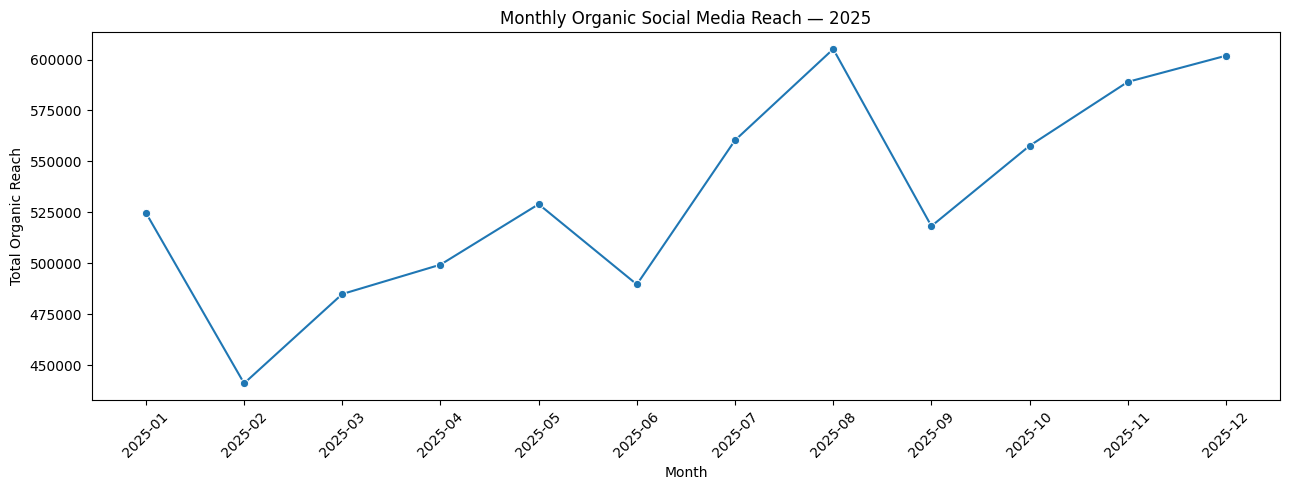

In [33]:

plt.figure(figsize=(13, 5))

sns.lineplot(
    data=monthly_social,
    x="month",
    y="total_reach",
    marker="o"
)

plt.title("Monthly Organic Social Media Reach — 2025")
plt.xlabel("Month")
plt.ylabel("Total Organic Reach")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


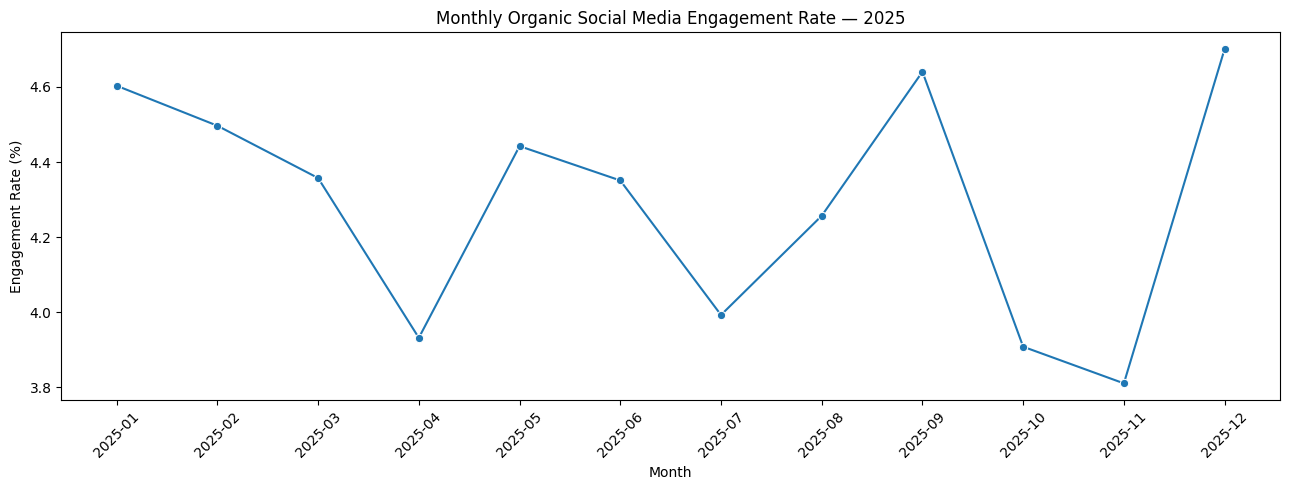

In [34]:

plt.figure(figsize=(13, 5))

sns.lineplot(
    data=monthly_social,
    x="month",
    y="engagement_rate",
    marker="o"
)

plt.title("Monthly Organic Social Media Engagement Rate — 2025")
plt.xlabel("Month")
plt.ylabel("Engagement Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


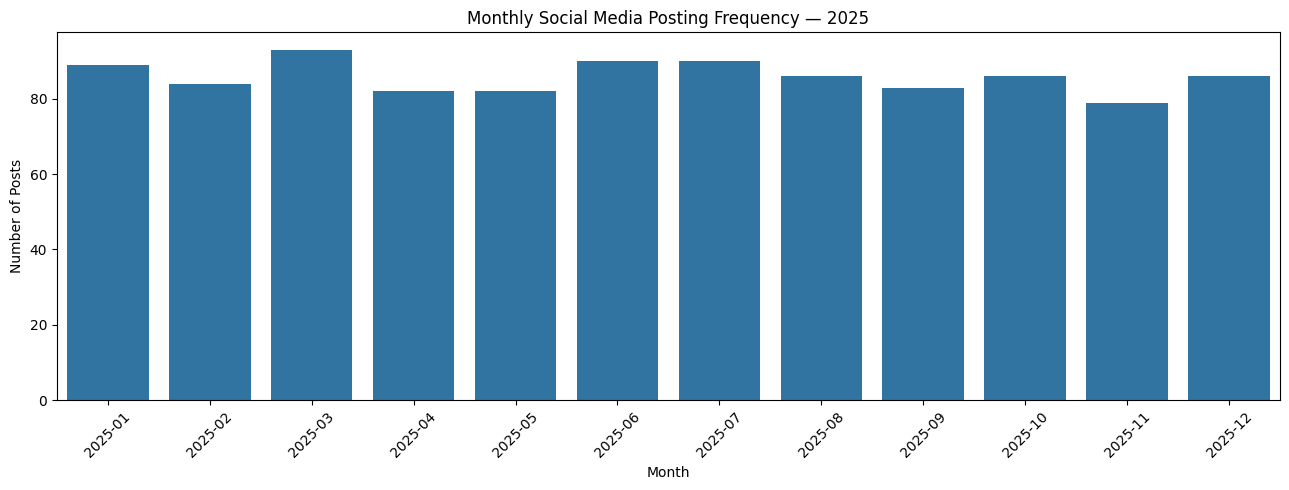

In [35]:

plt.figure(figsize=(13, 5))

sns.barplot(
    data=monthly_social,
    x="month",
    y="total_posts"
)

plt.title("Monthly Social Media Posting Frequency — 2025")
plt.xlabel("Month")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 6.6 Platform vs Content Format Analysis

Evaluate the performance of different content formats across Instagram,
Facebook, and YouTube to identify platform-specific content opportunities.

In [36]:

# Platform and content format analysis

platform_content = (
    social_analysis.groupby(["platform", "content_type"])
    .agg(
        total_posts=("post_id", "nunique"),
        avg_reach=("reach", "mean"),
        avg_engagements=("total_engagements", "mean"),
        avg_engagement_rate=("engagement_rate", "mean"),
        total_link_clicks=("link_clicks", "sum")
    )
    .reset_index()
    .round(2)
)

display(
    platform_content.sort_values(
        ["platform", "avg_engagement_rate"],
        ascending=[True, False]
    )
)


,platform,content_type,total_posts,avg_reach,avg_engagements,avg_engagement_rate,total_link_clicks
1,Facebook,Reel,102,"5,884.56",165.90,2.91,9074
0,Facebook,Carousel,76,"3,769.70",104.53,2.70,4588
2,Facebook,Static,84,"3,019.36",60.94,2.11,3925
4,Instagram,Reel,122,"8,018.43",384.68,4.83,16213
3,Instagram,Carousel,121,"6,243.99",280.57,4.48,12641
5,Instagram,Static,136,"4,758.70",155.07,3.47,9184
6,Instagram,Story,133,"3,030.07",88.26,3.04,5979
8,YouTube,Short,142,"10,414.15",570.56,5.75,22810
7,YouTube,Educational Video,114,"8,757.55",435.00,5.30,13723


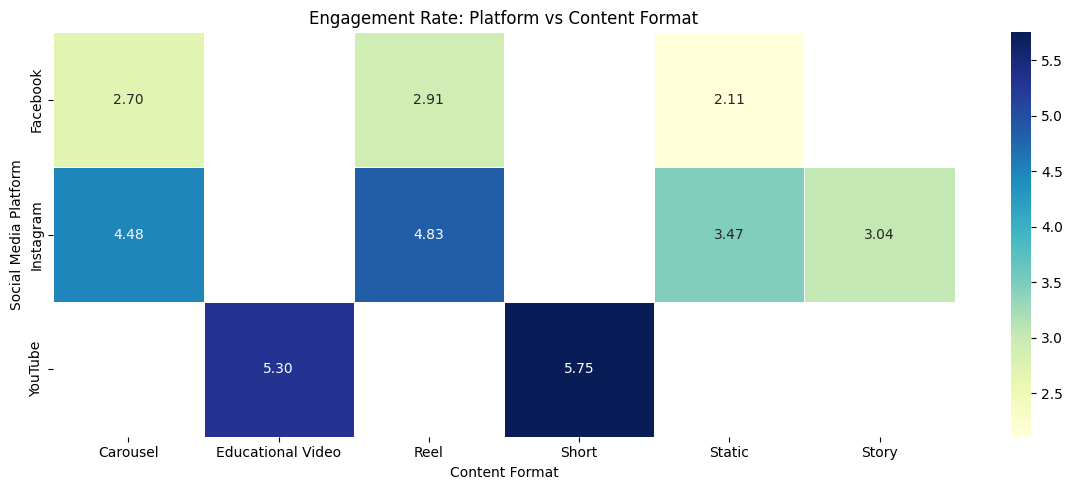

In [37]:

engagement_pivot = platform_content.pivot(
    index="platform",
    columns="content_type",
    values="avg_engagement_rate"
)

plt.figure(figsize=(12, 5))

sns.heatmap(
    engagement_pivot,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Engagement Rate: Platform vs Content Format")
plt.xlabel("Content Format")
plt.ylabel("Social Media Platform")
plt.tight_layout()
plt.show()


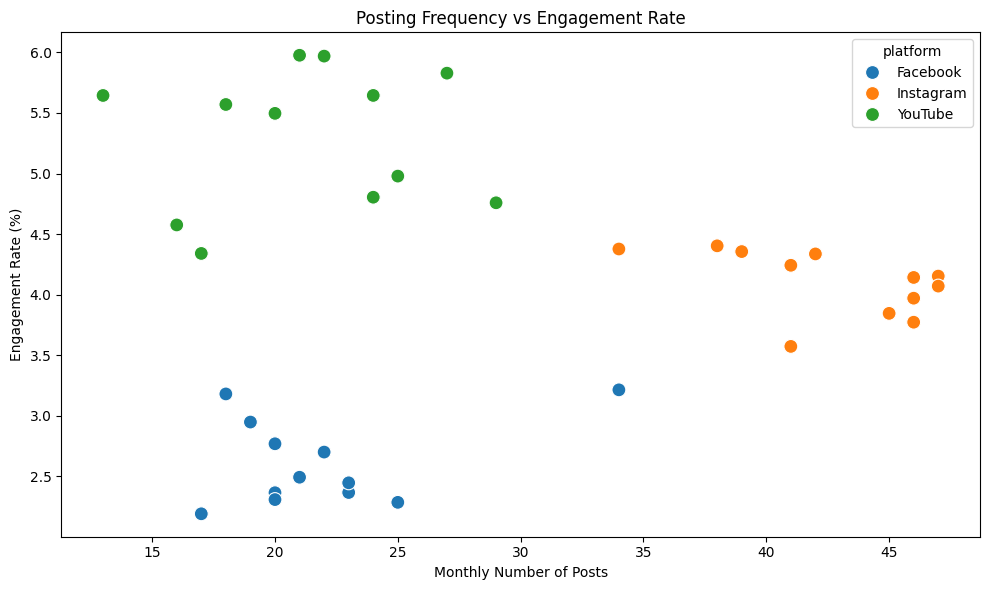

Correlation: 0.04


In [38]:

frequency_engagement = (
    social_analysis.groupby(
        ["platform", "month"]
    )
    .agg(
        total_posts=("post_id", "nunique"),
        total_reach=("reach", "sum"),
        total_engagements=("total_engagements", "sum")
    )
    .reset_index()
)

frequency_engagement["engagement_rate"] = (
    frequency_engagement["total_engagements"]
    / frequency_engagement["total_reach"] * 100
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=frequency_engagement,
    x="total_posts",
    y="engagement_rate",
    hue="platform",
    s=100
)

plt.title("Posting Frequency vs Engagement Rate")
plt.xlabel("Monthly Number of Posts")
plt.ylabel("Engagement Rate (%)")
plt.tight_layout()
plt.show()

print(
    "Correlation:",
    frequency_engagement[
        ["total_posts", "engagement_rate"]
    ].corr().iloc[0, 1].round(3)
)


In [39]:

# Platform-wise correlation analysis

platform_correlations = (
    frequency_engagement.groupby("platform")
    .apply(
        lambda x: x["total_posts"].corr(
            x["engagement_rate"]
        ),
        include_groups=False
    )
    .reset_index(name="posting_engagement_correlation")
)

display(platform_correlations.round(3))


,platform,posting_engagement_correlation
0,Facebook,0.32
1,Instagram,-0.50
2,YouTube,0.05


In [40]:

print("Website Traffic Dataset Shape:")
print(website_traffic.shape)

print("\nColumn Names:")
print(website_traffic.columns.tolist())

print("\nDataset Information:")
display(website_traffic.head())

print("\nData Types:")
print(website_traffic.dtypes)


Website Traffic Dataset Shape:
(2920, 9)

Column Names:
['date', 'channel', 'sessions', 'new_users', 'product_views', 'add_to_cart', 'checkout_started', 'purchases', 'revenue']

Dataset Information:


,date,channel,sessions,new_users,product_views,add_to_cart,checkout_started,purchases,revenue
0,2025-01-01,Organic Social,253,192,451,16,7,1,883.26
1,2025-01-01,Paid Social,243,194,438,16,7,0,0.00
2,2025-01-01,Paid Search,187,134,256,18,8,1,951.62
3,2025-01-01,Organic Search,186,119,302,16,9,1,"1,075.96"
4,2025-01-01,Email,88,30,161,10,5,1,"1,108.00"



Data Types:
date                datetime64[ns]
channel                     object
sessions                     int64
new_users                    int64
product_views                int64
add_to_cart                  int64
checkout_started             int64
purchases                    int64
revenue                    float64
dtype: object


### 6.7 Website Traffic and Marketing Channel Attribution

Analyze website traffic, customer acquisition, conversion performance,
and revenue generated by different marketing channels.

In [41]:

# Channel-level performance analysis

channel_performance = (
    website_traffic.groupby("channel")
    .agg(
        total_sessions=("sessions", "sum"),
        total_new_users=("new_users", "sum"),
        total_product_views=("product_views", "sum"),
        total_add_to_cart=("add_to_cart", "sum"),
        total_checkouts=("checkout_started", "sum"),
        total_purchases=("purchases", "sum"),
        total_revenue=("revenue", "sum")
    )
    .reset_index()
)

# Calculate conversion metrics

channel_performance["purchase_conversion_rate"] = (
    channel_performance["total_purchases"]
    / channel_performance["total_sessions"] * 100
)

channel_performance["add_to_cart_rate"] = (
    channel_performance["total_add_to_cart"]
    / channel_performance["total_sessions"] * 100
)

channel_performance["checkout_rate"] = (
    channel_performance["total_checkouts"]
    / channel_performance["total_sessions"] * 100
)

channel_performance["average_order_value"] = (
    channel_performance["total_revenue"]
    / channel_performance["total_purchases"].replace(0, np.nan)
)

channel_performance["revenue_per_session"] = (
    channel_performance["total_revenue"]
    / channel_performance["total_sessions"]
)

channel_performance = channel_performance.round(2)

display(
    channel_performance.sort_values(
        "total_revenue",
        ascending=False
    )
)


,channel,total_sessions,total_new_users,total_product_views,total_add_to_cart,total_checkouts,total_purchases,total_revenue,purchase_conversion_rate,add_to_cart_rate,checkout_rate,average_order_value,revenue_per_session
5,Paid Search,87709,62976,145380,8138,4500,815,"852,686.82",0.93,9.28,5.13,"1,046.24",9.72
3,Organic Search,92441,58986,150919,6695,3638,524,"544,792.91",0.57,7.24,3.94,"1,039.68",5.89
1,Email,38498,13301,63709,4263,2265,467,"482,266.74",1.21,11.07,5.88,"1,032.69",12.53
4,Organic Social,111585,84628,183187,6408,3490,418,"435,707.33",0.37,5.74,3.13,"1,042.36",3.90
6,Paid Social,97174,77595,159539,6078,3274,330,"339,559.69",0.34,6.25,3.37,"1,028.97",3.49
0,Direct,24175,11425,39176,1884,896,32,"33,364.88",0.13,7.79,3.71,"1,042.65",1.38
2,Influencer,24082,19572,40029,1133,467,0,0.00,0.00,4.70,1.94,NaN,0.00
7,Referral,9621,5789,15725,492,109,0,0.00,0.00,5.11,1.13,NaN,0.00


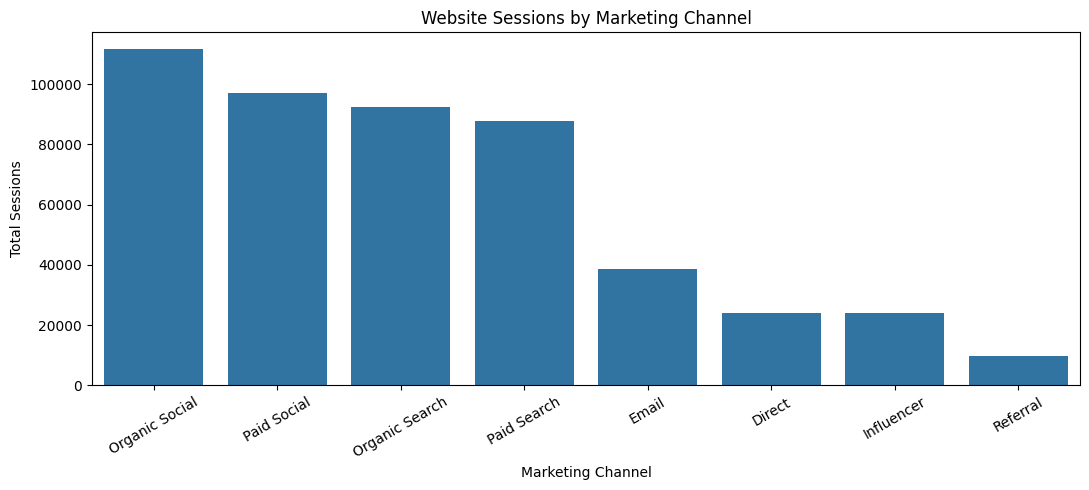

In [42]:

plt.figure(figsize=(11, 5))

sns.barplot(
    data=channel_performance.sort_values(
        "total_sessions",
        ascending=False
    ),
    x="channel",
    y="total_sessions"
)

plt.title("Website Sessions by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Total Sessions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


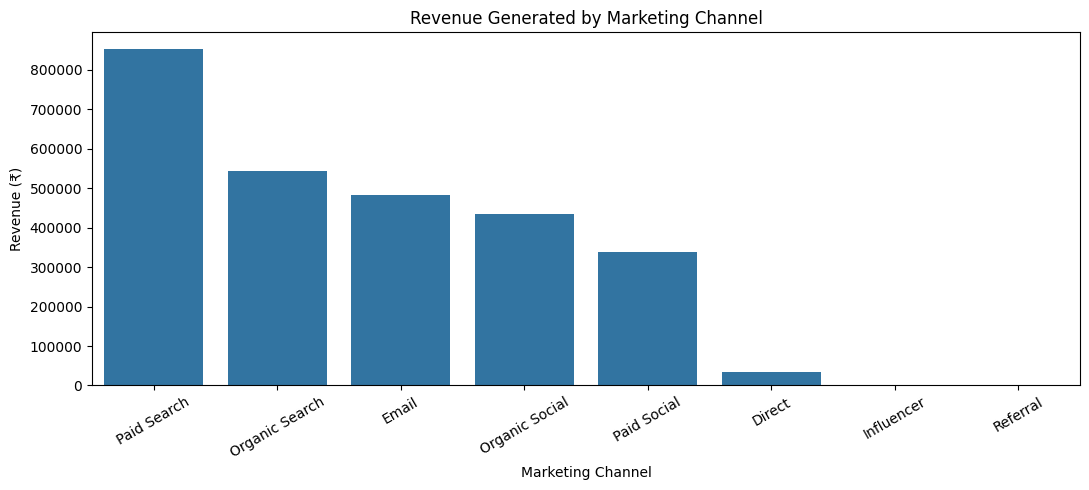

In [43]:

plt.figure(figsize=(11, 5))

sns.barplot(
    data=channel_performance.sort_values(
        "total_revenue",
        ascending=False
    ),
    x="channel",
    y="total_revenue"
)

plt.title("Revenue Generated by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


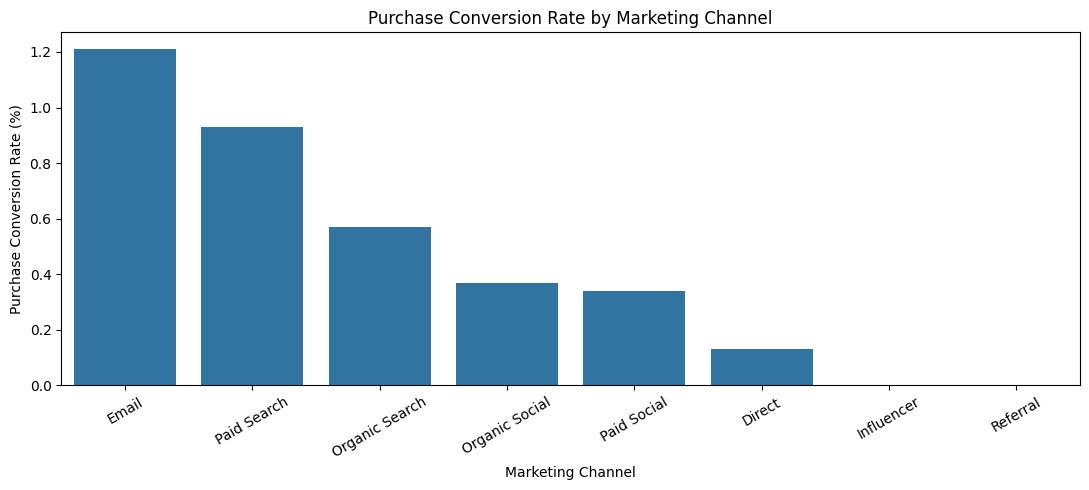

In [44]:

plt.figure(figsize=(11, 5))

sns.barplot(
    data=channel_performance.sort_values(
        "purchase_conversion_rate",
        ascending=False
    ),
    x="channel",
    y="purchase_conversion_rate"
)

plt.title("Purchase Conversion Rate by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Purchase Conversion Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [45]:

# Compare organic and paid social performance

social_channels = channel_performance[
    channel_performance["channel"].isin(
        ["Organic Social", "Paid Social"]
    )
].copy()

display(
    social_channels[
        [
            "channel",
            "total_sessions",
            "total_new_users",
            "total_purchases",
            "total_revenue",
            "purchase_conversion_rate",
            "average_order_value",
            "revenue_per_session"
        ]
    ]
)


,channel,total_sessions,total_new_users,total_purchases,total_revenue,purchase_conversion_rate,average_order_value,revenue_per_session
4,Organic Social,111585,84628,418,"435,707.33",0.37,"1,042.36",3.90
6,Paid Social,97174,77595,330,"339,559.69",0.34,"1,028.97",3.49


In [46]:

# Aggregate overall marketing funnel

funnel = pd.DataFrame({
    "Stage": [
        "Sessions",
        "Product Views",
        "Add to Cart",
        "Checkout Started",
        "Purchases"
    ],
    "Count": [
        website_traffic["sessions"].sum(),
        website_traffic["product_views"].sum(),
        website_traffic["add_to_cart"].sum(),
        website_traffic["checkout_started"].sum(),
        website_traffic["purchases"].sum()
    ]
})

funnel["Conversion_From_Previous_Stage"] = (
    funnel["Count"] / funnel["Count"].shift(1) * 100
)

funnel["Overall_Conversion"] = (
    funnel["Count"] / funnel["Count"].iloc[0] * 100
)

display(funnel.round(2))


,Stage,Count,Conversion_From_Previous_Stage,Overall_Conversion
0,Sessions,485285,NaN,100.00
1,Product Views,797664,164.37,164.37
2,Add to Cart,35091,4.40,7.23
3,Checkout Started,18639,53.12,3.84
4,Purchases,2586,13.87,0.53


In [47]:

print("Ad Performance Dataset Shape:")
print(ad_performance.shape)

print("\nColumn Names:")
print(ad_performance.columns.tolist())

print("\nData Types:")
print(ad_performance.dtypes)

print("\nSample Records:")
display(ad_performance.head())

print("\nMissing Values:")
display(ad_performance.isnull().sum())


Ad Performance Dataset Shape:
(1145, 12)

Column Names:
['date', 'campaign_id', 'platform', 'campaign_type', 'impressions', 'reach', 'clicks', 'spend', 'landing_page_views', 'add_to_cart', 'purchases', 'revenue']

Data Types:
date                  datetime64[ns]
campaign_id                   object
platform                      object
campaign_type                 object
impressions                    int64
reach                          int64
clicks                         int64
spend                        float64
landing_page_views             int64
add_to_cart                    int64
purchases                      int64
revenue                      float64
dtype: object

Sample Records:


,date,campaign_id,platform,campaign_type,impressions,reach,clicks,spend,landing_page_views,add_to_cart,purchases,revenue
0,2025-01-01,C001,Meta Ads,Conversion,27533,21731,472,"4,423.47",399,24,3,"2,957.00"
1,2025-01-02,C001,Meta Ads,Conversion,25631,22029,170,"4,291.97",151,16,2,"2,027.90"
2,2025-01-03,C001,Meta Ads,Conversion,21158,17942,191,"3,803.17",173,14,2,"2,124.50"
3,2025-01-04,C001,Meta Ads,Conversion,32313,25835,433,"4,273.84",383,38,5,"5,784.80"
4,2025-01-05,C001,Meta Ads,Conversion,29869,21080,415,"4,079.36",379,31,4,"4,282.55"



Missing Values:


,0
date,0
campaign_id,0
platform,0
campaign_type,0
impressions,0
reach,0
clicks,0
spend,0
landing_page_views,0
add_to_cart,0


In [48]:

# ==========================================
# PAID MARKETING PERFORMANCE ANALYSIS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create a copy
ads = ad_performance.copy()

# Convert date column
ads['date'] = pd.to_datetime(ads['date'])

# Calculate advertising KPIs
ads['CTR'] = np.where(
    ads['impressions'] > 0,
    (ads['clicks'] / ads['impressions']) * 100,
    0
)

ads['CPC'] = np.where(
    ads['clicks'] > 0,
    ads['spend'] / ads['clicks'],
    0
)

ads['CPM'] = np.where(
    ads['impressions'] > 0,
    (ads['spend'] / ads['impressions']) * 1000,
    0
)

ads['Conversion_Rate'] = np.where(
    ads['clicks'] > 0,
    (ads['purchases'] / ads['clicks']) * 100,
    0
)

ads['CPA'] = np.where(
    ads['purchases'] > 0,
    ads['spend'] / ads['purchases'],
    0
)

ads['ROAS'] = np.where(
    ads['spend'] > 0,
    ads['revenue'] / ads['spend'],
    0
)

# Display calculated metrics
display(ads.head())

print("Paid Advertising KPI Calculation Completed")


,date,campaign_id,platform,campaign_type,impressions,reach,clicks,spend,landing_page_views,add_to_cart,purchases,revenue,CTR,CPC,CPM,Conversion_Rate,CPA,ROAS
0,2025-01-01,C001,Meta Ads,Conversion,27533,21731,472,"4,423.47",399,24,3,"2,957.00",1.71,9.37,160.66,0.64,"1,474.49",0.67
1,2025-01-02,C001,Meta Ads,Conversion,25631,22029,170,"4,291.97",151,16,2,"2,027.90",0.66,25.25,167.45,1.18,"2,145.99",0.47
2,2025-01-03,C001,Meta Ads,Conversion,21158,17942,191,"3,803.17",173,14,2,"2,124.50",0.90,19.91,179.75,1.05,"1,901.59",0.56
3,2025-01-04,C001,Meta Ads,Conversion,32313,25835,433,"4,273.84",383,38,5,"5,784.80",1.34,9.87,132.26,1.15,854.77,1.35
4,2025-01-05,C001,Meta Ads,Conversion,29869,21080,415,"4,079.36",379,31,4,"4,282.55",1.39,9.83,136.58,0.96,"1,019.84",1.05


Paid Advertising KPI Calculation Completed


In [49]:

# Overall paid advertising performance

total_spend = ads['spend'].sum()
total_revenue = ads['revenue'].sum()
total_impressions = ads['impressions'].sum()
total_clicks = ads['clicks'].sum()
total_purchases = ads['purchases'].sum()

overall_ctr = (total_clicks / total_impressions) * 100
overall_cpc = total_spend / total_clicks
overall_roas = total_revenue / total_spend
overall_cpa = total_spend / total_purchases

print("NOVA SKIN - PAID ADVERTISING OVERVIEW")
print("-" * 45)

print(f"Total Ad Spend: ₹{total_spend:,.2f}")
print(f"Total Ad Revenue: ₹{total_revenue:,.2f}")
print(f"Total Impressions: {total_impressions:,}")
print(f"Total Clicks: {total_clicks:,}")
print(f"Total Purchases: {total_purchases:,}")

print(f"Overall CTR: {overall_ctr:.2f}%")
print(f"Overall CPC: ₹{overall_cpc:.2f}")
print(f"Overall CPA: ₹{overall_cpa:.2f}")
print(f"Overall ROAS: {overall_roas:.2f}x")


NOVA SKIN - PAID ADVERTISING OVERVIEW
---------------------------------------------
Total Ad Spend: ₹2,404,606.80
Total Ad Revenue: ₹4,800,648.63
Total Impressions: 15,380,403
Total Clicks: 262,880
Total Purchases: 3,792
Overall CTR: 1.71%
Overall CPC: ₹9.15
Overall CPA: ₹634.13
Overall ROAS: 2.00x


In [50]:

campaign_analysis = ads.groupby(
    ['campaign_id', 'platform', 'campaign_type']
).agg(
    total_spend=('spend', 'sum'),
    total_revenue=('revenue', 'sum'),
    impressions=('impressions', 'sum'),
    clicks=('clicks', 'sum'),
    purchases=('purchases', 'sum')
).reset_index()

campaign_analysis['CTR'] = (
    campaign_analysis['clicks'] /
    campaign_analysis['impressions'] * 100
)

campaign_analysis['CPC'] = (
    campaign_analysis['total_spend'] /
    campaign_analysis['clicks']
)

campaign_analysis['ROAS'] = (
    campaign_analysis['total_revenue'] /
    campaign_analysis['total_spend']
)

campaign_analysis['CPA'] = (
    campaign_analysis['total_spend'] /
    campaign_analysis['purchases'].replace(0, np.nan)
)

display(
    campaign_analysis.sort_values(
        by='ROAS', ascending=False
    )
)


,campaign_id,platform,campaign_type,total_spend,total_revenue,impressions,clicks,purchases,CTR,CPC,ROAS,CPA
9,C010,Google Ads,Shopping,"226,905.53","1,144,732.07",1331358,36563,738,2.75,6.21,5.04,307.46
7,C008,Meta Ads,Conversion,"172,421.55","736,192.44",1394757,22252,483,1.60,7.75,4.27,356.98
8,C009,Meta Ads,Conversion,"235,335.39","558,419.70",1822062,25901,526,1.42,9.09,2.37,447.41
6,C007,Google Ads,Search,"103,790.16","232,493.45",596156,15061,220,2.53,6.89,2.24,471.77
13,C014,Google Ads,Shopping,"126,181.12","274,649.92",650315,15645,249,2.41,8.07,2.18,506.75
3,C004,Google Ads,Shopping,"121,832.74","247,710.35",660342,16538,233,2.50,7.37,2.03,522.89
1,C002,Meta Ads,Conversion,"111,580.72","208,173.80",812094,10662,135,1.31,10.47,1.87,826.52
11,C012,Google Ads,Search,"208,156.28","353,694.40",1092607,22831,349,2.09,9.12,1.70,596.44
2,C003,Google Ads,Search,"140,539.74","195,465.10",825749,21964,186,2.66,6.40,1.39,755.59
10,C011,Meta Ads,Conversion,"364,254.88","437,731.80",2365339,26389,286,1.12,13.80,1.20,"1,273.62"


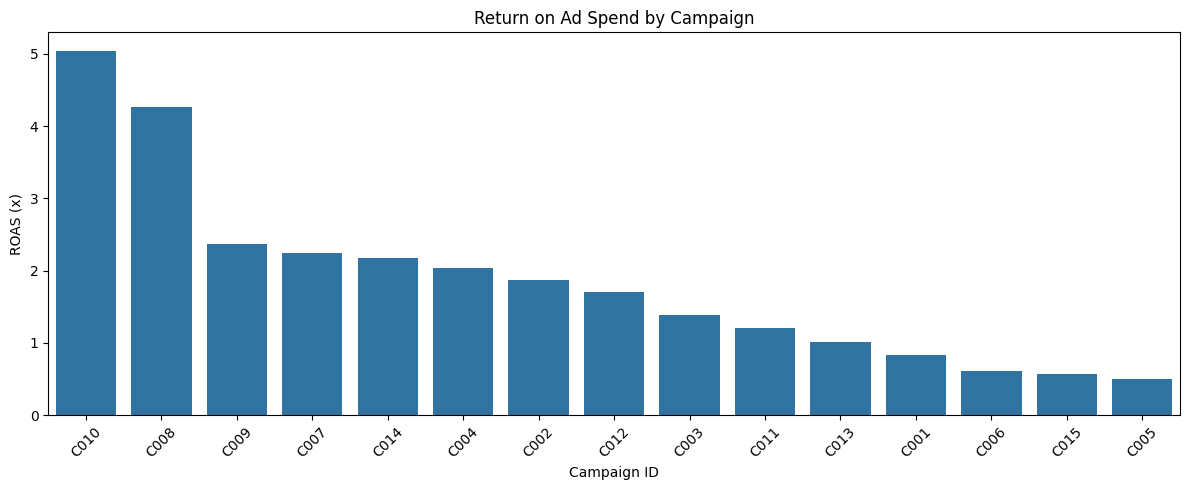

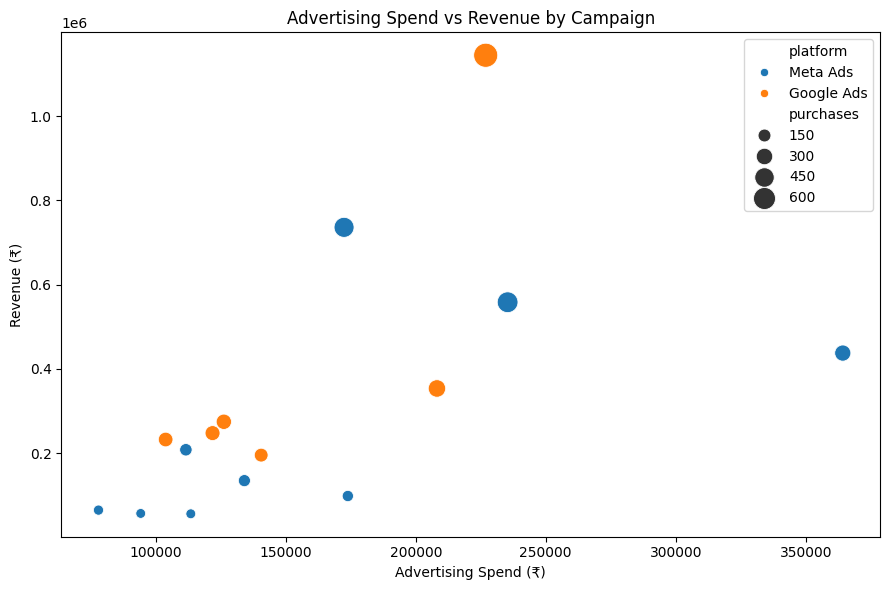

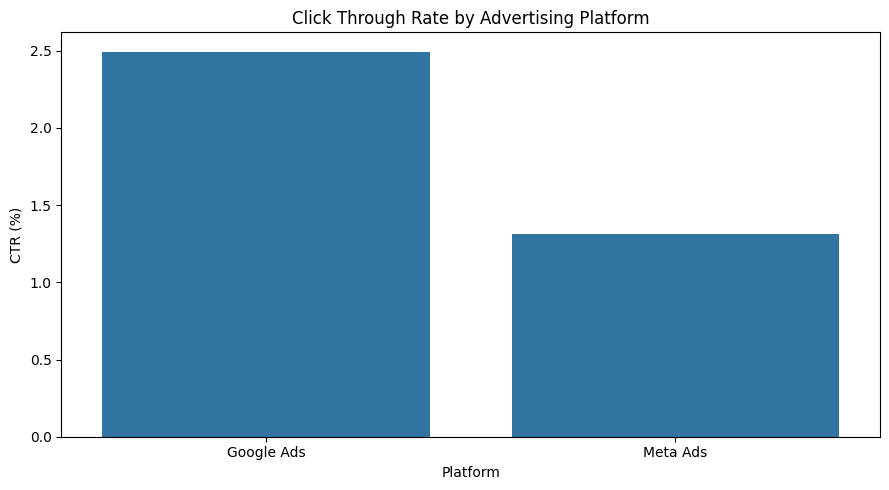

In [51]:

# 1. ROAS by Campaign

plt.figure(figsize=(12, 5))

sns.barplot(
    data=campaign_analysis.sort_values('ROAS', ascending=False),
    x='campaign_id',
    y='ROAS'
)

plt.title('Return on Ad Spend by Campaign')
plt.xlabel('Campaign ID')
plt.ylabel('ROAS (x)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 2. Advertising Spend vs Revenue

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=campaign_analysis,
    x='total_spend',
    y='total_revenue',
    hue='platform',
    size='purchases',
    sizes=(50, 300)
)

plt.title('Advertising Spend vs Revenue by Campaign')
plt.xlabel('Advertising Spend (₹)')
plt.ylabel('Revenue (₹)')
plt.tight_layout()
plt.show()


# 3. CTR by Platform

platform_analysis = ads.groupby('platform').agg(
    impressions=('impressions', 'sum'),
    clicks=('clicks', 'sum')
).reset_index()

platform_analysis['CTR'] = (
    platform_analysis['clicks'] /
    platform_analysis['impressions'] * 100
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=platform_analysis,
    x='platform',
    y='CTR'
)

plt.title('Click Through Rate by Advertising Platform')
plt.xlabel('Platform')
plt.ylabel('CTR (%)')
plt.tight_layout()
plt.show()


In [52]:

# ==========================================
# PLATFORM-WISE PAID MARKETING ANALYSIS
# ==========================================

platform_performance = ads.groupby('platform').agg(
    total_spend=('spend', 'sum'),
    total_revenue=('revenue', 'sum'),
    total_impressions=('impressions', 'sum'),
    total_clicks=('clicks', 'sum'),
    total_purchases=('purchases', 'sum')
).reset_index()

platform_performance['CTR'] = (
    platform_performance['total_clicks'] /
    platform_performance['total_impressions'] * 100
)

platform_performance['ROAS'] = (
    platform_performance['total_revenue'] /
    platform_performance['total_spend']
)

platform_performance['CPA'] = (
    platform_performance['total_spend'] /
    platform_performance['total_purchases'].replace(0, np.nan)
)

platform_performance['Conversion_Rate'] = (
    platform_performance['total_purchases'] /
    platform_performance['total_clicks'].replace(0, np.nan) * 100
)

display(
    platform_performance.sort_values(
        'ROAS', ascending=False
    ).round(2)
)


,platform,total_spend,total_revenue,total_impressions,total_clicks,total_purchases,CTR,ROAS,CPA,Conversion_Rate
0,Google Ads,"927,405.57","2,448,745.29",5156527,128602,1975,2.49,2.64,469.57,1.54
1,Meta Ads,"1,477,201.23","2,351,903.34",10223876,134278,1817,1.31,1.59,812.99,1.35


,campaign_type,total_spend,total_revenue,total_clicks,total_purchases,ROAS,CPA
3,Shopping,"474,919.39","1,667,092.34",68746,1220,3.51,389.28
0,Conversion,"1,303,324.58","2,253,509.81",115041,1721,1.73,757.31
2,Search,"452,486.18","781,652.95",59856,755,1.73,599.32
1,Retargeting,"173,876.65","98,393.53",19237,96,0.57,"1,811.22"


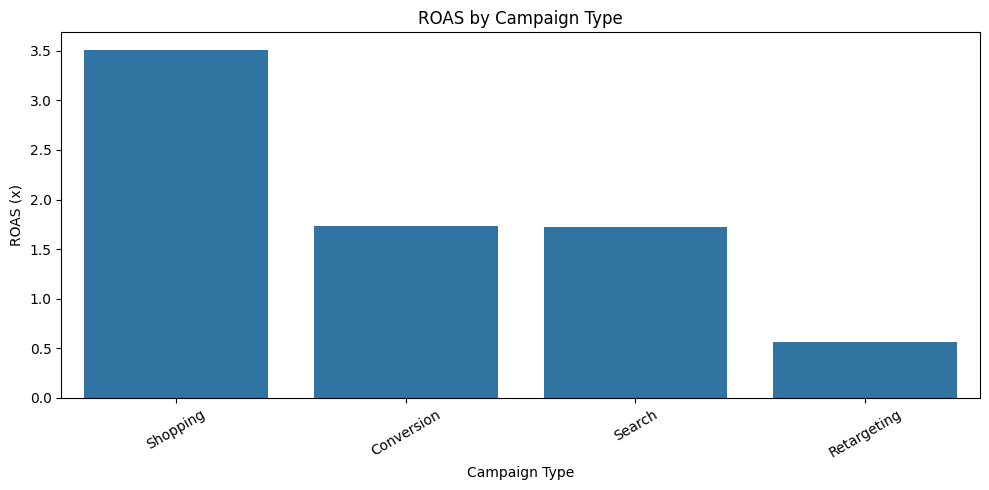

In [53]:

# ==========================================
# CAMPAIGN TYPE ANALYSIS
# ==========================================

campaign_type_analysis = ads.groupby('campaign_type').agg(
    total_spend=('spend', 'sum'),
    total_revenue=('revenue', 'sum'),
    total_clicks=('clicks', 'sum'),
    total_purchases=('purchases', 'sum')
).reset_index()

campaign_type_analysis['ROAS'] = (
    campaign_type_analysis['total_revenue'] /
    campaign_type_analysis['total_spend']
)

campaign_type_analysis['CPA'] = (
    campaign_type_analysis['total_spend'] /
    campaign_type_analysis['total_purchases'].replace(0, np.nan)
)

display(
    campaign_type_analysis.sort_values(
        'ROAS', ascending=False
    ).round(2)
)

# Visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=campaign_type_analysis.sort_values(
        'ROAS', ascending=False
    ),
    x='campaign_type',
    y='ROAS'
)

plt.title('ROAS by Campaign Type')
plt.xlabel('Campaign Type')
plt.ylabel('ROAS (x)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


,month,total_spend,total_revenue,total_purchases,total_clicks,ROAS,CPA
0,2025-01,"100,884.05","86,139.97",82,8995,0.85,"1,230.29"
1,2025-02,"134,376.37","225,520.23",152,13471,1.68,884.06
2,2025-03,"23,644.06","17,456.06",17,3039,0.74,"1,390.83"
3,2025-04,"125,182.46","157,626.34",147,13721,1.26,851.58
4,2025-05,"161,587.97","183,658.56",175,16815,1.14,923.36
5,2025-06,"22,173.72","17,005.83",16,2906,0.77,"1,385.86"
6,2025-07,"171,603.07","196,589.60",184,17495,1.15,932.63
7,2025-08,"76,745.31","134,690.70",128,10711,1.76,599.57
8,2025-09,"199,006.24","761,494.28",508,25734,3.83,391.74
9,2025-10,"409,536.42","1,277,668.07",1008,53301,3.12,406.29


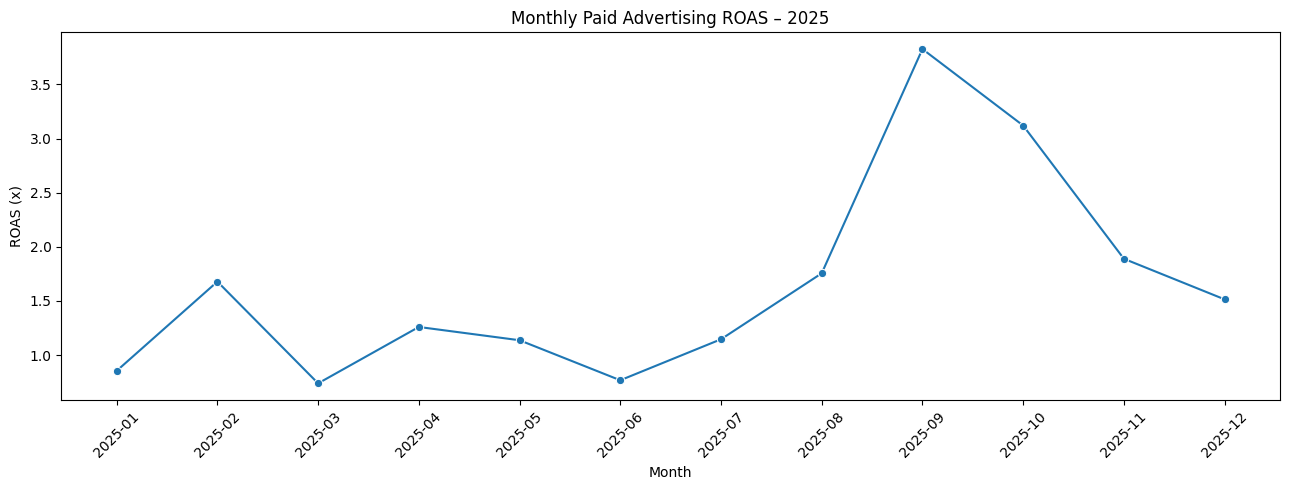

In [54]:

# ==========================================
# MONTHLY PAID AD PERFORMANCE
# ==========================================

ads['month'] = ads['date'].dt.to_period('M').astype(str)

monthly_ads = ads.groupby('month').agg(
    total_spend=('spend', 'sum'),
    total_revenue=('revenue', 'sum'),
    total_purchases=('purchases', 'sum'),
    total_clicks=('clicks', 'sum')
).reset_index()

monthly_ads['ROAS'] = (
    monthly_ads['total_revenue'] /
    monthly_ads['total_spend']
)

monthly_ads['CPA'] = (
    monthly_ads['total_spend'] /
    monthly_ads['total_purchases'].replace(0, np.nan)
)

display(monthly_ads.round(2))

# Monthly ROAS trend
plt.figure(figsize=(13, 5))

sns.lineplot(
    data=monthly_ads,
    x='month',
    y='ROAS',
    marker='o'
)

plt.title('Monthly Paid Advertising ROAS – 2025')
plt.xlabel('Month')
plt.ylabel('ROAS (x)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [55]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load email campaign dataset
email_df = pd.read_csv("email_campaigns.csv")

# Display first 5 records
display(email_df.head())

# Dataset dimensions
print("Dataset Shape:", email_df.shape)

# Column names
print("\nColumn Names:")
print(email_df.columns.tolist())

# Data types
print("\nData Types:")
print(email_df.dtypes)

# Missing values
print("\nMissing Values:")
print(email_df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", email_df.duplicated().sum())

# Statistical summary
display(email_df.describe(include="all"))


,email_id,send_date,campaign_name,email_type,recipients,delivered,opens,clicks,orders,revenue
0,E0001,2025-01-03,Seasonal | Jan 03,Seasonal,61401,59809,17154,798,143,"178,390.67"
1,E0002,2025-01-10,Product Education | Jan 10,Product Education,40161,39810,11038,630,66,"67,158.97"
2,E0003,2025-01-17,Seasonal | Jan 17,Seasonal,26612,26373,6818,290,47,"51,709.72"
3,E0004,2025-01-24,Welcome | Jan 24,Welcome,39548,38963,19483,1471,197,"233,143.89"
4,E0005,2025-01-31,Seasonal | Jan 31,Seasonal,55283,53980,14992,784,148,"167,979.66"


Dataset Shape: (52, 10)

Column Names:
['email_id', 'send_date', 'campaign_name', 'email_type', 'recipients', 'delivered', 'opens', 'clicks', 'orders', 'revenue']

Data Types:
email_id          object
send_date         object
campaign_name     object
email_type        object
recipients         int64
delivered          int64
opens              int64
clicks             int64
orders             int64
revenue          float64
dtype: object

Missing Values:
email_id         0
send_date        0
campaign_name    0
email_type       0
recipients       0
delivered        0
opens            0
clicks           0
orders           0
revenue          0
dtype: int64

Duplicate Records: 0


,email_id,send_date,campaign_name,email_type,recipients,delivered,opens,clicks,orders,revenue
count,52,52,52,52,52.00,52.00,52.00,52.00,52.00,52.00
unique,52,52,52,6,NaN,NaN,NaN,NaN,NaN,NaN
top,E0001,2025-01-03,Seasonal | Jan 03,Seasonal,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,1,1,14,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,"42,962.58","42,099.88","14,635.96",960.90,156.71,"169,262.17"
std,NaN,NaN,NaN,NaN,"12,562.46","12,331.87","5,700.65",616.14,109.93,"118,810.65"
min,NaN,NaN,NaN,NaN,"18,461.00","17,929.00","4,838.00",236.00,24.00,"25,307.62"
25%,NaN,NaN,NaN,NaN,"31,841.75","31,482.25","9,972.75",499.75,78.50,"78,261.01"
50%,NaN,NaN,NaN,NaN,"44,409.00","43,417.00","13,974.00",762.50,114.50,"125,765.46"
75%,NaN,NaN,NaN,NaN,"51,241.75","50,533.25","18,871.00","1,372.50",203.00,"234,825.60"


In [56]:

# Create a working copy
email_df = email_df.copy()

# 1. Convert send_date into datetime
email_df['send_date'] = pd.to_datetime(
    email_df['send_date']
)

# 2. Check missing values
print("Missing Values:")
print(email_df.isnull().sum())

# 3. Check duplicate email IDs
print("\nDuplicate Email IDs:",
      email_df['email_id'].duplicated().sum())

# 4. Validate delivery numbers
print("\nDelivered greater than Recipients:")
print((email_df['delivered'] > email_df['recipients']).sum())

# 5. Validate opens against deliveries
print("\nOpens greater than Delivered:")
print((email_df['opens'] > email_df['delivered']).sum())

# 6. Validate clicks against deliveries
print("\nClicks greater than Delivered:")
print((email_df['clicks'] > email_df['delivered']).sum())

# 7. Validate orders against clicks
print("\nOrders greater than Clicks:")
print((email_df['orders'] > email_df['clicks']).sum())

# 8. Check date range
print("\nCampaign Date Range:")
print("Start Date:", email_df['send_date'].min())
print("End Date:", email_df['send_date'].max())

# 9. Check email types
print("\nEmail Types:")
print(email_df['email_type'].value_counts())

# 10. Final data types
print("\nUpdated Data Types:")
print(email_df.dtypes)


Missing Values:
email_id         0
send_date        0
campaign_name    0
email_type       0
recipients       0
delivered        0
opens            0
clicks           0
orders           0
revenue          0
dtype: int64

Duplicate Email IDs: 0

Delivered greater than Recipients:
0

Opens greater than Delivered:
0

Clicks greater than Delivered:
0

Orders greater than Clicks:
0

Campaign Date Range:
Start Date: 2025-01-03 00:00:00
End Date: 2025-12-26 00:00:00

Email Types:
email_type
Seasonal             14
Promotional           9
Welcome               8
Product Education     7
Launch                7
Abandoned Cart        7
Name: count, dtype: int64

Updated Data Types:
email_id                 object
send_date        datetime64[ns]
campaign_name            object
email_type               object
recipients                int64
delivered                 int64
opens                     int64
clicks                    int64
orders                    int64
revenue                 float64
d

In [57]:

# Create campaign-level KPI columns

email_df['delivery_rate'] = (
    email_df['delivered'] / email_df['recipients']
) * 100

email_df['open_rate'] = (
    email_df['opens'] / email_df['delivered']
) * 100

email_df['click_through_rate'] = (
    email_df['clicks'] / email_df['delivered']
) * 100

email_df['click_to_open_rate'] = (
    email_df['clicks'] / email_df['opens']
) * 100

email_df['conversion_rate'] = (
    email_df['orders'] / email_df['clicks']
) * 100

email_df['revenue_per_email'] = (
    email_df['revenue'] / email_df['delivered']
)

email_df['average_order_value'] = np.where(
    email_df['orders'] > 0,
    email_df['revenue'] / email_df['orders'],
    0
)

# Display campaign-level KPIs
display(
    email_df[[
        'campaign_name',
        'email_type',
        'delivery_rate',
        'open_rate',
        'click_through_rate',
        'click_to_open_rate',
        'conversion_rate',
        'revenue_per_email',
        'average_order_value'
    ]].head(10).round(2)
)


,campaign_name,email_type,delivery_rate,open_rate,click_through_rate,click_to_open_rate,conversion_rate,revenue_per_email,average_order_value
0,Seasonal | Jan 03,Seasonal,97.41,28.68,1.33,4.65,17.92,2.98,"1,247.49"
1,Product Education | Jan 10,Product Education,99.13,27.73,1.58,5.71,10.48,1.69,"1,017.56"
2,Seasonal | Jan 17,Seasonal,99.10,25.85,1.10,4.25,16.21,1.96,"1,100.21"
3,Welcome | Jan 24,Welcome,98.52,50.00,3.78,7.55,13.39,5.98,"1,183.47"
4,Seasonal | Jan 31,Seasonal,97.64,27.77,1.45,5.23,18.88,3.11,"1,135.00"
5,Seasonal | Feb 07,Seasonal,98.17,26.56,0.91,3.42,13.68,1.23,988.13
6,Launch | Feb 14,Launch,97.15,37.21,2.48,6.68,18.16,4.13,914.98
7,Product Education | Feb 21,Product Education,98.54,32.02,1.71,5.35,21.14,4.11,"1,133.97"
8,Launch | Feb 28,Launch,98.56,35.08,2.11,6.01,15.18,2.94,917.91
9,Promotional | Mar 07,Promotional,98.91,25.16,1.54,6.14,15.71,2.41,990.96


In [58]:

# Calculate overall KPIs using aggregated totals

total_recipients = email_df['recipients'].sum()
total_delivered = email_df['delivered'].sum()
total_opens = email_df['opens'].sum()
total_clicks = email_df['clicks'].sum()
total_orders = email_df['orders'].sum()
total_revenue = email_df['revenue'].sum()

overall_kpis = {
    'Total Campaigns': len(email_df),

    'Total Recipients': total_recipients,

    'Total Delivered': total_delivered,

    'Delivery Rate (%)':
        (total_delivered / total_recipients) * 100,

    'Total Opens': total_opens,

    'Open Rate (%)':
        (total_opens / total_delivered) * 100,

    'Total Clicks': total_clicks,

    'Click Through Rate (%)':
        (total_clicks / total_delivered) * 100,

    'Click To Open Rate (%)':
        (total_clicks / total_opens) * 100,

    'Total Orders': total_orders,

    'Conversion Rate (%)':
        (total_orders / total_clicks) * 100,

    'Total Revenue': total_revenue,

    'Revenue Per Delivered Email':
        total_revenue / total_delivered,

    'Average Order Value':
        total_revenue / total_orders
}

kpi_summary = pd.DataFrame(
    overall_kpis.items(),
    columns=['KPI', 'Value']
)

display(kpi_summary.round(2))


,KPI,Value
0,Total Campaigns,52.00
1,Total Recipients,"2,234,054.00"
2,Total Delivered,"2,189,194.00"
3,Delivery Rate (%),97.99
4,Total Opens,"761,070.00"
5,Open Rate (%),34.76
6,Total Clicks,"49,967.00"
7,Click Through Rate (%),2.28
8,Click To Open Rate (%),6.57
9,Total Orders,"8,149.00"


In [59]:

# Group data by email type

email_type_analysis = email_df.groupby('email_type').agg(
    total_campaigns=('email_id', 'count'),
    total_recipients=('recipients', 'sum'),
    total_delivered=('delivered', 'sum'),
    total_opens=('opens', 'sum'),
    total_clicks=('clicks', 'sum'),
    total_orders=('orders', 'sum'),
    total_revenue=('revenue', 'sum')
).reset_index()

# Calculate aggregated performance rates

email_type_analysis['delivery_rate'] = (
    email_type_analysis['total_delivered'] /
    email_type_analysis['total_recipients']
) * 100

email_type_analysis['open_rate'] = (
    email_type_analysis['total_opens'] /
    email_type_analysis['total_delivered']
) * 100

email_type_analysis['click_through_rate'] = (
    email_type_analysis['total_clicks'] /
    email_type_analysis['total_delivered']
) * 100

email_type_analysis['conversion_rate'] = (
    email_type_analysis['total_orders'] /
    email_type_analysis['total_clicks']
) * 100

email_type_analysis['revenue_per_email'] = (
    email_type_analysis['total_revenue'] /
    email_type_analysis['total_delivered']
)

email_type_analysis['average_order_value'] = (
    email_type_analysis['total_revenue'] /
    email_type_analysis['total_orders']
)

# Sort by revenue
email_type_analysis = email_type_analysis.sort_values(
    by='total_revenue',
    ascending=False
)

display(email_type_analysis.round(2))


,email_type,total_campaigns,total_recipients,total_delivered,total_opens,total_clicks,total_orders,total_revenue,delivery_rate,open_rate,click_through_rate,conversion_rate,revenue_per_email,average_order_value
0,Abandoned Cart,7,310866,303384,133128,13470,2291,"2,427,511.80",97.59,43.88,4.44,17.01,8.00,"1,059.59"
5,Welcome,8,359128,352432,172363,13097,2142,"2,396,315.57",98.14,48.91,3.72,16.35,6.80,"1,118.73"
4,Seasonal,14,566233,554828,155321,7872,1300,"1,391,378.49",97.99,27.99,1.42,16.51,2.51,"1,070.29"
1,Launch,7,304614,298527,106623,6477,909,"947,458.28",98.00,35.72,2.17,14.03,3.17,"1,042.31"
3,Promotional,9,395259,387734,102787,4574,757,"832,472.17",98.10,26.51,1.18,16.55,2.15,"1,099.70"
2,Product Education,7,297954,292289,90848,4477,750,"806,496.40",98.10,31.08,1.53,16.75,2.76,"1,075.33"


In [60]:
import numpy as np
import pandas as pd

email_type_analysis = email_df.groupby('email_type').agg(
    total_campaigns=('email_id', 'nunique'),
    total_recipients=('recipients', 'sum'),
    total_delivered=('delivered', 'sum'),
    total_opens=('opens', 'sum'),
    total_clicks=('clicks', 'sum'),
    total_orders=('orders', 'sum'),
    total_revenue=('revenue', 'sum')
).reset_index()

# Performance metrics
email_type_analysis['delivery_rate'] = (
    email_type_analysis['total_delivered'] /
    email_type_analysis['total_recipients'] * 100
)

email_type_analysis['open_rate'] = (
    email_type_analysis['total_opens'] /
    email_type_analysis['total_delivered'] * 100
)

email_type_analysis['CTR'] = (
    email_type_analysis['total_clicks'] /
    email_type_analysis['total_delivered'] * 100
)

email_type_analysis['CTOR'] = (
    email_type_analysis['total_clicks'] /
    email_type_analysis['total_opens'] * 100
)

email_type_analysis['conversion_rate'] = (
    email_type_analysis['total_orders'] /
    email_type_analysis['total_clicks'] * 100
)

email_type_analysis['revenue_per_email'] = (
    email_type_analysis['total_revenue'] /
    email_type_analysis['total_delivered']
)

email_type_analysis['average_order_value'] = (
    email_type_analysis['total_revenue'] /
    email_type_analysis['total_orders']
)

email_type_analysis['revenue_per_campaign'] = (
    email_type_analysis['total_revenue'] /
    email_type_analysis['total_campaigns']
)

# Sort by revenue
email_type_analysis = email_type_analysis.sort_values(
    by='total_revenue',
    ascending=False
)

display(email_type_analysis.round(2))

,email_type,total_campaigns,total_recipients,total_delivered,total_opens,total_clicks,total_orders,total_revenue,delivery_rate,open_rate,CTR,CTOR,conversion_rate,revenue_per_email,average_order_value,revenue_per_campaign
0,Abandoned Cart,7,310866,303384,133128,13470,2291,"2,427,511.80",97.59,43.88,4.44,10.12,17.01,8.00,"1,059.59","346,787.40"
5,Welcome,8,359128,352432,172363,13097,2142,"2,396,315.57",98.14,48.91,3.72,7.60,16.35,6.80,"1,118.73","299,539.45"
4,Seasonal,14,566233,554828,155321,7872,1300,"1,391,378.49",97.99,27.99,1.42,5.07,16.51,2.51,"1,070.29","99,384.18"
1,Launch,7,304614,298527,106623,6477,909,"947,458.28",98.00,35.72,2.17,6.07,14.03,3.17,"1,042.31","135,351.18"
3,Promotional,9,395259,387734,102787,4574,757,"832,472.17",98.10,26.51,1.18,4.45,16.55,2.15,"1,099.70","92,496.91"
2,Product Education,7,297954,292289,90848,4477,750,"806,496.40",98.10,31.08,1.53,4.93,16.75,2.76,"1,075.33","115,213.77"


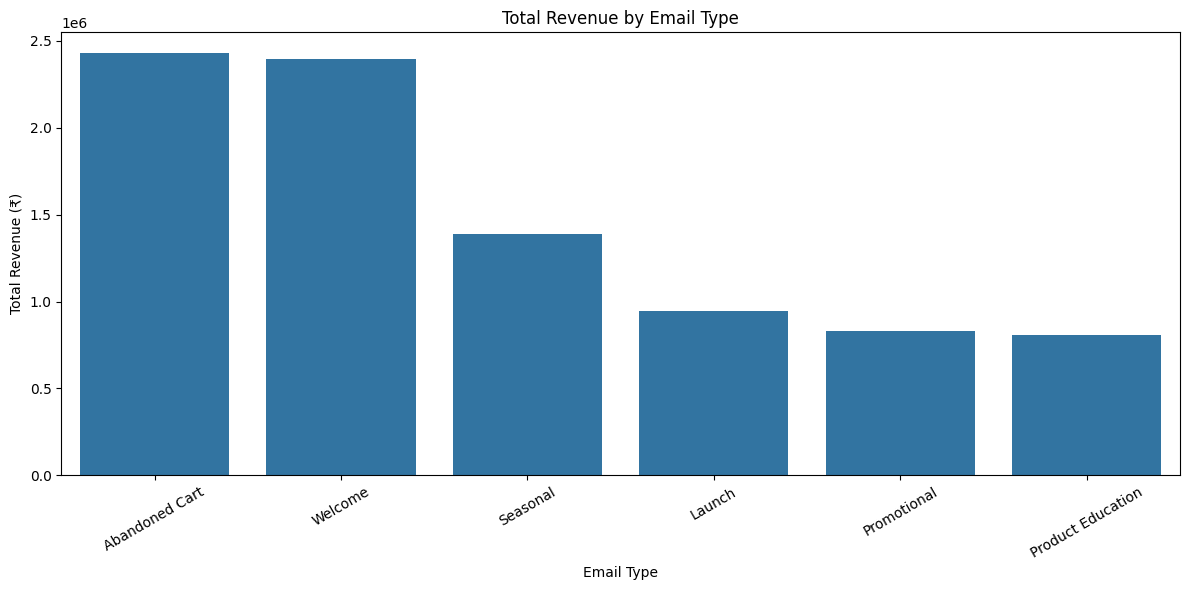

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=email_type_analysis,
    x='email_type',
    y='total_revenue'
)

plt.title('Total Revenue by Email Type')
plt.xlabel('Email Type')
plt.ylabel('Total Revenue (₹)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

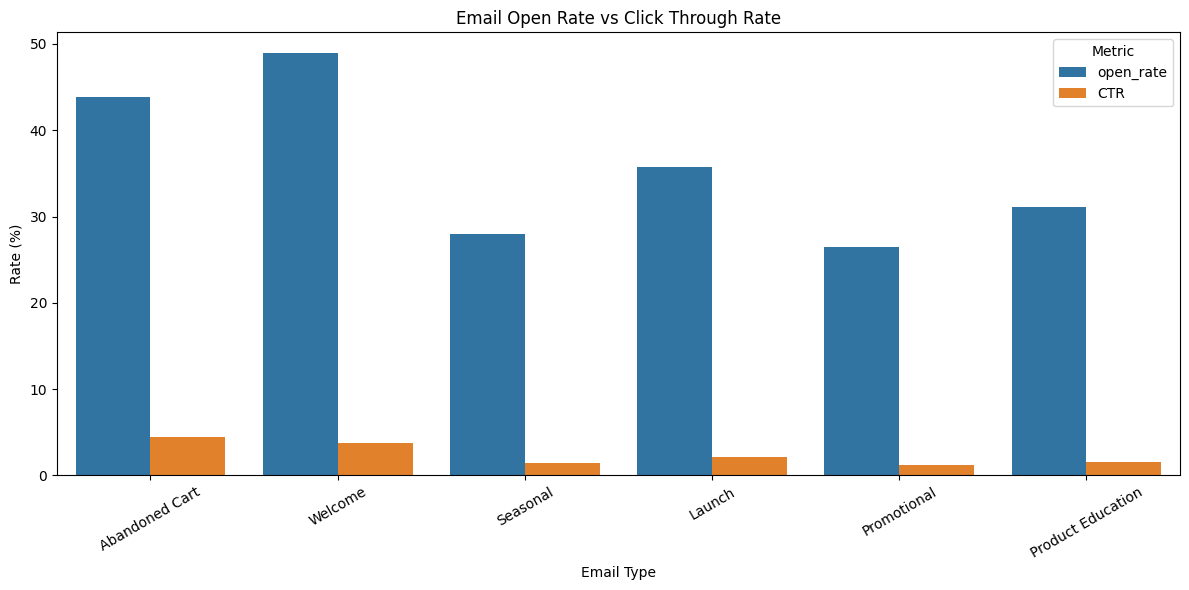

In [62]:
email_metrics = email_type_analysis.melt(
    id_vars='email_type',
    value_vars=['open_rate', 'CTR'],
    var_name='Metric',
    value_name='Rate'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=email_metrics,
    x='email_type',
    y='Rate',
    hue='Metric'
)

plt.title('Email Open Rate vs Click Through Rate')
plt.xlabel('Email Type')
plt.ylabel('Rate (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

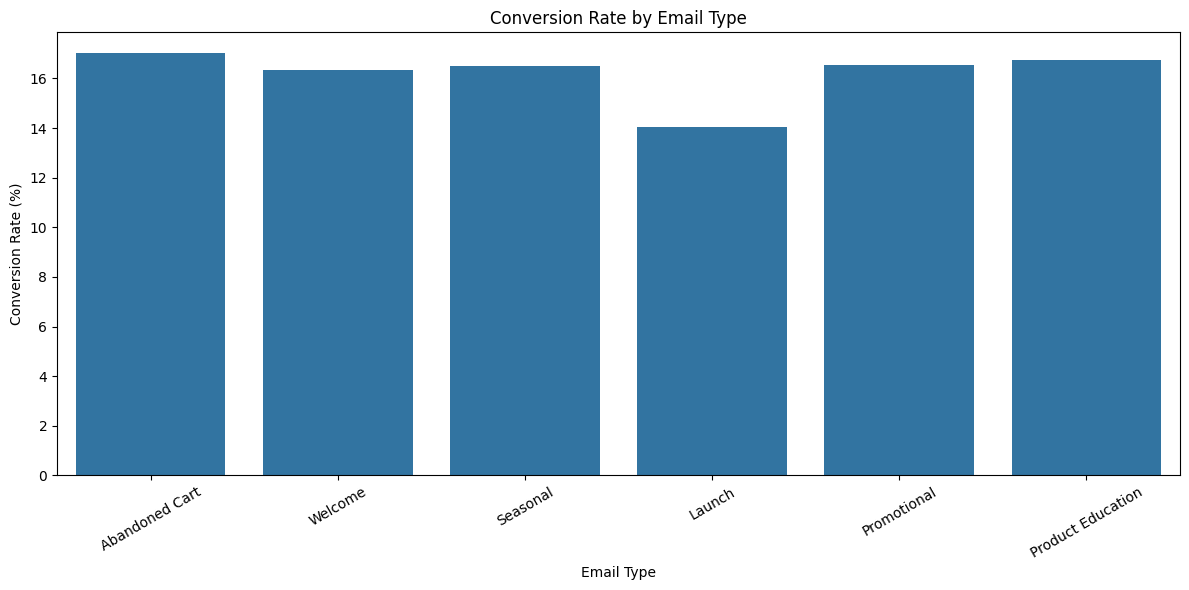

In [63]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=email_type_analysis,
    x='email_type',
    y='conversion_rate'
)

plt.title('Conversion Rate by Email Type')
plt.xlabel('Email Type')
plt.ylabel('Conversion Rate (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [64]:
# Convert send_date to datetime if not already converted
email_df['send_date'] = pd.to_datetime(email_df['send_date'])

# Extract month
email_df['month'] = email_df['send_date'].dt.to_period('M')

# Monthly email performance
monthly_email = email_df.groupby('month').agg(
    total_campaigns=('email_id', 'nunique'),
    total_recipients=('recipients', 'sum'),
    total_delivered=('delivered', 'sum'),
    total_opens=('opens', 'sum'),
    total_clicks=('clicks', 'sum'),
    total_orders=('orders', 'sum'),
    total_revenue=('revenue', 'sum')
).reset_index()

# Calculate monthly KPIs
monthly_email['delivery_rate'] = (
    monthly_email['total_delivered'] /
    monthly_email['total_recipients'] * 100
)

monthly_email['open_rate'] = (
    monthly_email['total_opens'] /
    monthly_email['total_delivered'] * 100
)

monthly_email['CTR'] = (
    monthly_email['total_clicks'] /
    monthly_email['total_delivered'] * 100
)

monthly_email['conversion_rate'] = (
    monthly_email['total_orders'] /
    monthly_email['total_clicks'] * 100
)

# Format month
monthly_email['month'] = monthly_email['month'].astype(str)

# Display results
display(monthly_email.round(2))

,month,total_campaigns,total_recipients,total_delivered,total_opens,total_clicks,total_orders,total_revenue,delivery_rate,open_rate,CTR,conversion_rate
0,2025-01,5,223005,218935,69485,3973,601,"698,382.91",98.17,31.74,1.81,15.13
1,2025-02,4,169975,166675,54994,3078,545,"538,868.01",98.06,32.99,1.85,17.71
2,2025-03,4,176890,173229,65203,4756,723,"813,475.70",97.93,37.64,2.75,15.20
3,2025-04,4,152105,148913,52989,3077,554,"583,276.27",97.90,35.58,2.07,18.00
4,2025-05,5,256822,251967,101531,8186,1320,"1,517,267.60",98.11,40.30,3.25,16.13
5,2025-06,4,165951,161041,59948,4412,602,"706,409.58",97.04,37.23,2.74,13.64
6,2025-07,4,234481,230112,78495,5621,967,"944,522.44",98.14,34.11,2.44,17.20
7,2025-08,5,229368,225780,73447,4803,810,"860,916.93",98.44,32.53,2.13,16.86
8,2025-09,4,146421,142542,40771,2039,310,"321,372.37",97.35,28.60,1.43,15.20
9,2025-10,5,181039,177180,71133,5864,1015,"1,064,615.05",97.87,40.15,3.31,17.31


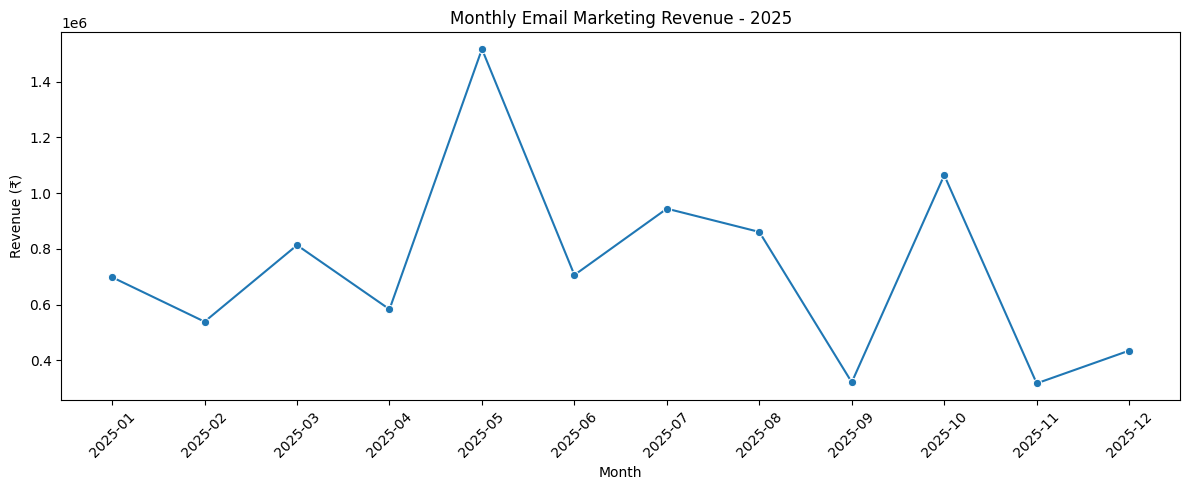

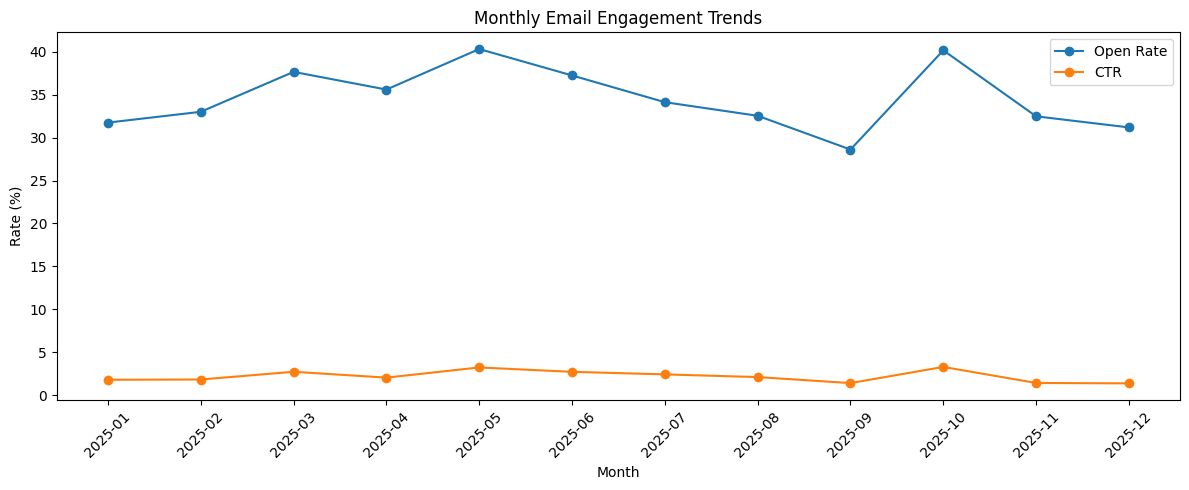

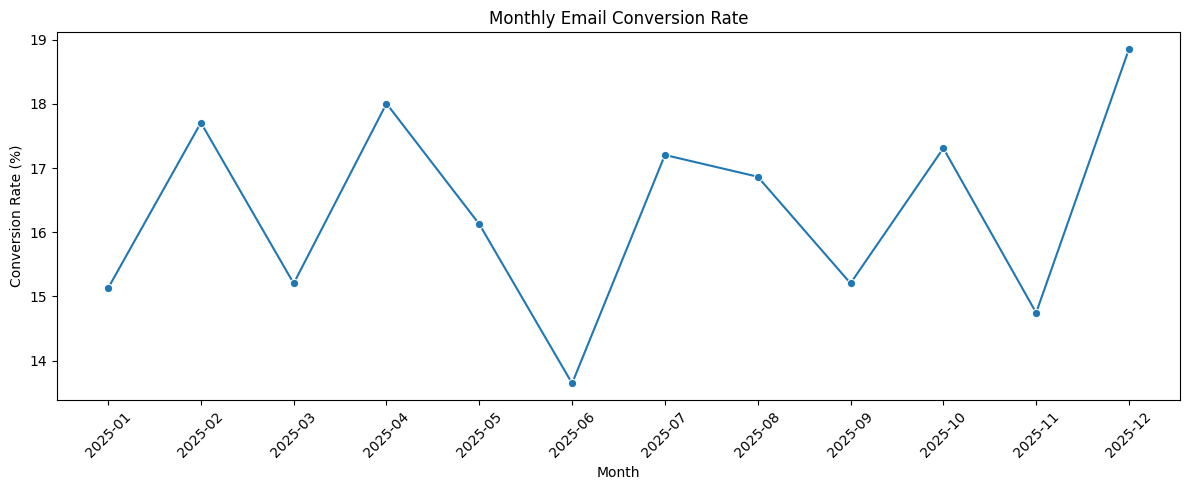

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

# Monthly Revenue
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_email,
    x='month',
    y='total_revenue',
    marker='o'
)
plt.title('Monthly Email Marketing Revenue - 2025')
plt.xlabel('Month')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Monthly Engagement Rates
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_email['month'],
    monthly_email['open_rate'],
    marker='o',
    label='Open Rate'
)

plt.plot(
    monthly_email['month'],
    monthly_email['CTR'],
    marker='o',
    label='CTR'
)

plt.title('Monthly Email Engagement Trends')
plt.xlabel('Month')
plt.ylabel('Rate (%)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


# Monthly Conversion Rate
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_email,
    x='month',
    y='conversion_rate',
    marker='o'
)
plt.title('Monthly Email Conversion Rate')
plt.xlabel('Month')
plt.ylabel('Conversion Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [66]:
# Step 4: Individual Email Campaign Performance

campaign_performance = email_df.copy()

# Calculate campaign KPIs

campaign_performance['delivery_rate'] = (
    campaign_performance['delivered'] /
    campaign_performance['recipients'] * 100
)

campaign_performance['open_rate'] = (
    campaign_performance['opens'] /
    campaign_performance['delivered'] * 100
)

campaign_performance['CTR'] = (
    campaign_performance['clicks'] /
    campaign_performance['delivered'] * 100
)

campaign_performance['click_to_open_rate'] = (
    campaign_performance['clicks'] /
    campaign_performance['opens'] * 100
)

campaign_performance['conversion_rate'] = (
    campaign_performance['orders'] /
    campaign_performance['clicks'] * 100
)

campaign_performance['revenue_per_email'] = (
    campaign_performance['revenue'] /
    campaign_performance['delivered']
)

campaign_performance['average_order_value'] = (
    campaign_performance['revenue'] /
    campaign_performance['orders']
)

# Top 10 campaigns by revenue

top_campaigns = campaign_performance.sort_values(
    by='revenue',
    ascending=False
).head(10)

# Bottom 10 campaigns by revenue

bottom_campaigns = campaign_performance.sort_values(
    by='revenue',
    ascending=True
).head(10)

# Display results

print("TOP 10 EMAIL CAMPAIGNS BY REVENUE")

display(top_campaigns[[
    'campaign_name',
    'email_type',
    'revenue',
    'open_rate',
    'CTR',
    'conversion_rate',
    'average_order_value'
]].round(2))


print("BOTTOM 10 EMAIL CAMPAIGNS BY REVENUE")

display(bottom_campaigns[[
    'campaign_name',
    'email_type',
    'revenue',
    'open_rate',
    'CTR',
    'conversion_rate',
    'average_order_value'
]].round(2))

TOP 10 EMAIL CAMPAIGNS BY REVENUE


,campaign_name,email_type,revenue,open_rate,CTR,conversion_rate,average_order_value
18,Abandoned Cart | May 09,Abandoned Cart,"523,849.28",44.55,4.54,22.44,"1,128.99"
41,Welcome | Oct 17,Welcome,"433,277.91",49.45,3.62,21.41,"1,110.97"
27,Abandoned Cart | Jul 11,Abandoned Cart,"418,520.21",39.36,4.23,17.72,959.91
10,Welcome | Mar 14,Welcome,"408,017.43",52.85,4.34,19.36,"1,111.76"
20,Abandoned Cart | May 23,Abandoned Cart,"370,265.33",47.46,4.47,17.67,"1,085.82"
42,Abandoned Cart | Oct 24,Abandoned Cart,"348,300.67",43.97,4.45,16.13,981.13
31,Abandoned Cart | Aug 08,Abandoned Cart,"330,487.16",45.25,5.01,21.11,"1,042.55"
23,Abandoned Cart | Jun 13,Abandoned Cart,"320,828.52",44.32,4.07,11.32,"1,188.25"
16,Welcome | Apr 25,Welcome,"299,484.32",52.98,4.15,18.51,"1,105.11"
17,Welcome | May 02,Welcome,"286,714.18",46.71,3.67,10.44,"1,230.53"


BOTTOM 10 EMAIL CAMPAIGNS BY REVENUE


,campaign_name,email_type,revenue,open_rate,CTR,conversion_rate,average_order_value
45,Seasonal | Nov 14,Seasonal,"25,307.62",26.98,1.32,10.17,"1,054.48"
35,Seasonal | Sep 05,Seasonal,"27,150.80",27.05,1.07,10.70,936.23
5,Seasonal | Feb 07,Seasonal,"44,465.66",26.56,0.91,13.68,988.13
2,Seasonal | Jan 17,Seasonal,"51,709.72",25.85,1.10,16.21,"1,100.21"
34,Product Education | Aug 29,Product Education,"60,867.78",33.24,1.60,10.42,"1,217.36"
40,Promotional | Oct 10,Promotional,"64,945.28",29.23,1.40,17.94,"1,064.68"
25,Promotional | Jun 27,Promotional,"66,259.61",25.77,1.30,11.25,"1,051.74"
48,Seasonal | Dec 05,Seasonal,"66,565.33",32.13,1.95,16.88,"1,024.08"
1,Product Education | Jan 10,Product Education,"67,158.97",27.73,1.58,10.48,"1,017.56"
15,Promotional | Apr 18,Promotional,"71,790.36",30.48,1.20,18.06,"1,040.44"


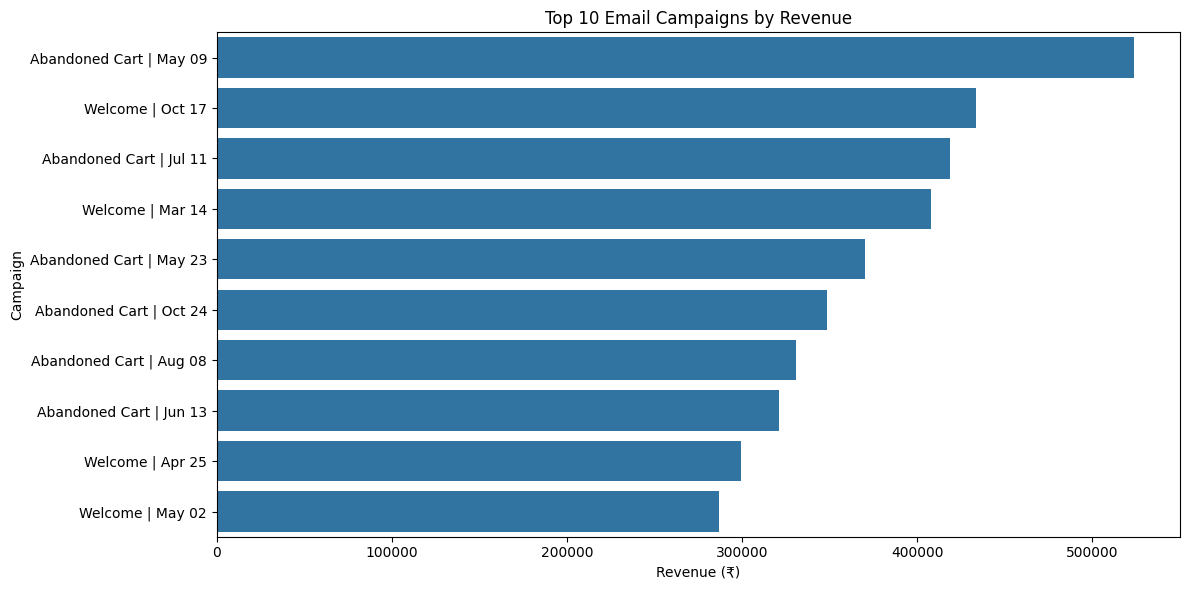

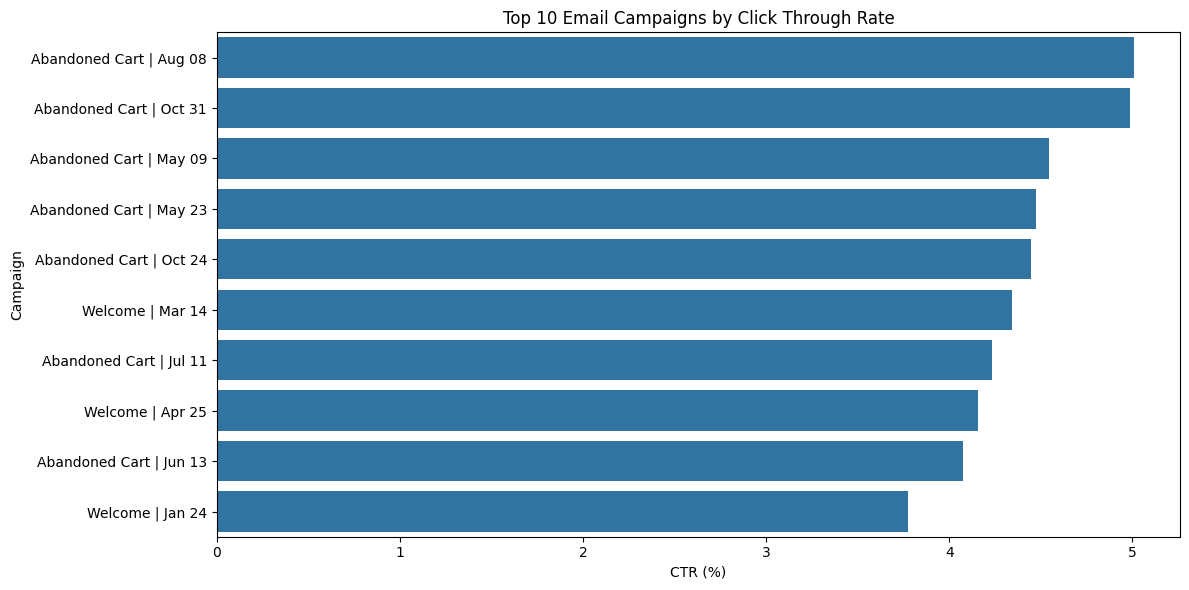

In [67]:
# Top 10 campaigns by revenue

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_campaigns,
    x='revenue',
    y='campaign_name'
)

plt.title('Top 10 Email Campaigns by Revenue')
plt.xlabel('Revenue (₹)')
plt.ylabel('Campaign')
plt.tight_layout()
plt.show()


# Top 10 campaigns by CTR

top_ctr = campaign_performance.sort_values(
    by='CTR',
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_ctr,
    x='CTR',
    y='campaign_name'
)

plt.title('Top 10 Email Campaigns by Click Through Rate')
plt.xlabel('CTR (%)')
plt.ylabel('Campaign')
plt.tight_layout()
plt.show()

In [68]:

# ==========================================
# INFLUENCER MARKETING - DATA EXPLORATION
# ==========================================

# 1. Dataset shape
print("Dataset Shape:", influencer_campaigns.shape)

# 2. First 5 records
display(influencer_campaigns.head())

# 3. Column names
print("\nColumn Names:")
print(influencer_campaigns.columns.tolist())

# 4. Data types
print("\nData Types:")
print(influencer_campaigns.dtypes)

# 5. Dataset information
print("\nDataset Information:")
influencer_campaigns.info()

# 6. Statistical summary
print("\nStatistical Summary:")
display(influencer_campaigns.describe(include='all').T)

# 7. Missing values
print("\nMissing Values:")
print(influencer_campaigns.isnull().sum())

# 8. Duplicate records
print("\nDuplicate Records:",
      influencer_campaigns.duplicated().sum())


Dataset Shape: (8, 14)


,influencer_id,campaign_id,influencer_name,influencer_type,platform,followers,campaign_date,spend,reach,impressions,engagements,link_clicks,orders,revenue
0,INF001,INF-C01,Aarohi Mehta,Micro,Instagram,82000,2025-07-27,"47,209.08",25881,41693,1653,407,88,"95,477.74"
1,INF002,INF-C02,Riya Kapoor,Micro,Instagram,115000,2025-11-10,"43,594.06",43787,67340,2908,567,120,"132,562.45"
2,INF003,INF-C03,Kavya Sharma,Mid-tier,Instagram,285000,2025-07-31,"135,211.94",52054,73337,4256,1132,108,"127,870.83"
3,INF004,INF-C04,Neha Verma,Mid-tier,YouTube,410000,2025-03-11,"96,337.87",102914,131312,3815,2093,384,"390,425.70"
4,INF005,INF-C05,Ishita Rao,Micro,Instagram,67000,2025-01-06,"57,318.99",22057,36318,1667,593,115,"133,752.90"



Column Names:
['influencer_id', 'campaign_id', 'influencer_name', 'influencer_type', 'platform', 'followers', 'campaign_date', 'spend', 'reach', 'impressions', 'engagements', 'link_clicks', 'orders', 'revenue']

Data Types:
influencer_id              object
campaign_id                object
influencer_name            object
influencer_type            object
platform                   object
followers                   int64
campaign_date      datetime64[ns]
spend                     float64
reach                       int64
impressions                 int64
engagements                 int64
link_clicks                 int64
orders                      int64
revenue                   float64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   influencer_id    8 non-null      object        
 1 

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
influencer_id,8,8,INF001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
campaign_id,8,8,INF-C01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
influencer_name,8,8,Aarohi Mehta,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
influencer_type,8,2,Micro,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
platform,8,2,Instagram,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
followers,8.00,NaN,NaN,NaN,"206,500.00","67,000.00","90,250.00","180,000.00","302,500.00","410,000.00","134,867.13"
campaign_date,8,NaN,NaN,NaN,2025-06-16 06:00:00,2025-01-06 00:00:00,2025-02-28 00:00:00,2025-07-29 00:00:00,2025-08-26 12:00:00,2025-11-10 00:00:00,NaN
spend,8.00,NaN,NaN,NaN,"80,725.29","30,969.14","46,305.32","76,828.43","106,733.17","137,921.02","41,888.01"
reach,8.00,NaN,NaN,NaN,"58,388.50","21,019.00","24,925.00","47,920.50","66,564.50","144,948.00","43,943.34"
impressions,8.00,NaN,NaN,NaN,"78,698.00","24,629.00","40,349.25","67,578.00","87,830.75","187,139.00","54,632.19"



Missing Values:
influencer_id      0
campaign_id        0
influencer_name    0
influencer_type    0
platform           0
followers          0
campaign_date      0
spend              0
reach              0
impressions        0
engagements        0
link_clicks        0
orders             0
revenue            0
dtype: int64

Duplicate Records: 0


In [69]:

# ==========================================
# STEP 2: DATA VALIDATION & FEATURE ENGINEERING
# ==========================================

# Check missing values
print("Missing Values:")
print(influencer_campaigns.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(influencer_campaigns.duplicated().sum())

# Check duplicate campaign IDs
print("\nDuplicate Campaign IDs:")
print(influencer_campaigns['campaign_id'].duplicated().sum())

# Validate numerical values
numeric_columns = [
    'followers', 'spend', 'reach', 'impressions',
    'engagements', 'link_clicks', 'orders', 'revenue'
]

print("\nNegative Values:")
print((influencer_campaigns[numeric_columns] < 0).sum())

# ==========================================
# FEATURE ENGINEERING
# ==========================================

influencer_campaigns['engagement_rate'] = (
    influencer_campaigns['engagements'] /
    influencer_campaigns['reach'] * 100
)

influencer_campaigns['CTR'] = (
    influencer_campaigns['link_clicks'] /
    influencer_campaigns['impressions'] * 100
)

influencer_campaigns['conversion_rate'] = (
    influencer_campaigns['orders'] /
    influencer_campaigns['link_clicks'] * 100
)

influencer_campaigns['ROAS'] = (
    influencer_campaigns['revenue'] /
    influencer_campaigns['spend']
)

influencer_campaigns['cost_per_order'] = (
    influencer_campaigns['spend'] /
    influencer_campaigns['orders']
)

influencer_campaigns['CPM'] = (
    influencer_campaigns['spend'] /
    influencer_campaigns['impressions'] * 1000
)

influencer_campaigns['revenue_per_order'] = (
    influencer_campaigns['revenue'] /
    influencer_campaigns['orders']
)

# Handle division by zero
new_columns = [
    'engagement_rate', 'CTR', 'conversion_rate',
    'ROAS', 'cost_per_order', 'CPM',
    'revenue_per_order'
]

influencer_campaigns[new_columns] = (
    influencer_campaigns[new_columns].replace(
        [float('inf'), float('-inf')], 0
    ).fillna(0)
)

# Display updated dataset
print("\nUpdated Dataset:")
display(influencer_campaigns.head())

print("\nDataset Shape:")
print(influencer_campaigns.shape)


Missing Values:
influencer_id      0
campaign_id        0
influencer_name    0
influencer_type    0
platform           0
followers          0
campaign_date      0
spend              0
reach              0
impressions        0
engagements        0
link_clicks        0
orders             0
revenue            0
dtype: int64

Duplicate Records:
0

Duplicate Campaign IDs:
0

Negative Values:
followers      0
spend          0
reach          0
impressions    0
engagements    0
link_clicks    0
orders         0
revenue        0
dtype: int64

Updated Dataset:


,influencer_id,campaign_id,influencer_name,influencer_type,platform,followers,campaign_date,spend,reach,impressions,engagements,link_clicks,orders,revenue,engagement_rate,CTR,conversion_rate,ROAS,cost_per_order,CPM,revenue_per_order
0,INF001,INF-C01,Aarohi Mehta,Micro,Instagram,82000,2025-07-27,"47,209.08",25881,41693,1653,407,88,"95,477.74",6.39,0.98,21.62,2.02,536.47,"1,132.30","1,084.97"
1,INF002,INF-C02,Riya Kapoor,Micro,Instagram,115000,2025-11-10,"43,594.06",43787,67340,2908,567,120,"132,562.45",6.64,0.84,21.16,3.04,363.28,647.37,"1,104.69"
2,INF003,INF-C03,Kavya Sharma,Mid-tier,Instagram,285000,2025-07-31,"135,211.94",52054,73337,4256,1132,108,"127,870.83",8.18,1.54,9.54,0.95,"1,251.96","1,843.71","1,183.99"
3,INF004,INF-C04,Neha Verma,Mid-tier,YouTube,410000,2025-03-11,"96,337.87",102914,131312,3815,2093,384,"390,425.70",3.71,1.59,18.35,4.05,250.88,733.66,"1,016.73"
4,INF005,INF-C05,Ishita Rao,Micro,Instagram,67000,2025-01-06,"57,318.99",22057,36318,1667,593,115,"133,752.90",7.56,1.63,19.39,2.33,498.43,"1,578.25","1,163.07"



Dataset Shape:
(8, 21)


In [70]:

# ==========================================
# STEP 3: INFLUENCER PERFORMANCE ANALYSIS
# ==========================================

influencer_analysis = influencer_campaigns.groupby(
    ['influencer_id', 'influencer_name', 'influencer_type', 'platform']
).agg(
    total_campaigns=('campaign_id', 'nunique'),
    followers=('followers', 'mean'),
    total_spend=('spend', 'sum'),
    total_reach=('reach', 'sum'),
    total_impressions=('impressions', 'sum'),
    total_engagements=('engagements', 'sum'),
    total_clicks=('link_clicks', 'sum'),
    total_orders=('orders', 'sum'),
    total_revenue=('revenue', 'sum')
).reset_index()

# Calculate weighted performance KPIs
influencer_analysis['engagement_rate'] = (
    influencer_analysis['total_engagements'] /
    influencer_analysis['total_reach'] * 100
)

influencer_analysis['CTR'] = (
    influencer_analysis['total_clicks'] /
    influencer_analysis['total_impressions'] * 100
)

influencer_analysis['conversion_rate'] = (
    influencer_analysis['total_orders'] /
    influencer_analysis['total_clicks'] * 100
)

influencer_analysis['ROAS'] = (
    influencer_analysis['total_revenue'] /
    influencer_analysis['total_spend']
)

influencer_analysis['cost_per_order'] = (
    influencer_analysis['total_spend'] /
    influencer_analysis['total_orders']
)

# Sort by revenue
influencer_analysis = influencer_analysis.sort_values(
    by='total_revenue', ascending=False
)

# Display results
display(influencer_analysis.round(2))


,influencer_id,influencer_name,influencer_type,platform,total_campaigns,followers,total_spend,total_reach,total_impressions,total_engagements,total_clicks,total_orders,total_revenue,engagement_rate,CTR,conversion_rate,ROAS,cost_per_order
5,INF006,Ananya Singh,Mid-tier,YouTube,1,"355,000.00","137,921.02",144948,187139,7025,2679,320,"412,240.05",4.85,1.43,11.94,2.99,431.00
3,INF004,Neha Verma,Mid-tier,YouTube,1,"410,000.00","96,337.87",102914,131312,3815,2093,384,"390,425.70",3.71,1.59,18.35,4.05,250.88
7,INF008,Sana Khan,Mid-tier,Instagram,1,"245,000.00","97,240.24",54448,67816,3098,1028,168,"156,121.54",5.69,1.52,16.34,1.61,578.81
4,INF005,Ishita Rao,Micro,Instagram,1,"67,000.00","57,318.99",22057,36318,1667,593,115,"133,752.90",7.56,1.63,19.39,2.33,498.43
1,INF002,Riya Kapoor,Micro,Instagram,1,"115,000.00","43,594.06",43787,67340,2908,567,120,"132,562.45",6.64,0.84,21.16,3.04,363.28
2,INF003,Kavya Sharma,Mid-tier,Instagram,1,"285,000.00","135,211.94",52054,73337,4256,1132,108,"127,870.83",8.18,1.54,9.54,0.95,"1,251.96"
0,INF001,Aarohi Mehta,Micro,Instagram,1,"82,000.00","47,209.08",25881,41693,1653,407,88,"95,477.74",6.39,0.98,21.62,2.02,536.47
6,INF007,Meera Joshi,Micro,Instagram,1,"93,000.00","30,969.14",21019,24629,1316,479,77,"75,714.91",6.26,1.94,16.08,2.44,402.20


In [71]:

# ==========================================
# STEP 4: INFLUENCER TYPE & PLATFORM ANALYSIS
# ==========================================

# 1. Performance by Influencer Type

type_analysis = influencer_campaigns.groupby(
    'influencer_type'
).agg(
    total_influencers=('influencer_id', 'nunique'),
    total_campaigns=('campaign_id', 'nunique'),
    total_spend=('spend', 'sum'),
    total_reach=('reach', 'sum'),
    total_impressions=('impressions', 'sum'),
    total_engagements=('engagements', 'sum'),
    total_clicks=('link_clicks', 'sum'),
    total_orders=('orders', 'sum'),
    total_revenue=('revenue', 'sum')
).reset_index()

# Calculate weighted KPIs
type_analysis['engagement_rate'] = (
    type_analysis['total_engagements'] /
    type_analysis['total_reach'] * 100
)

type_analysis['CTR'] = (
    type_analysis['total_clicks'] /
    type_analysis['total_impressions'] * 100
)

type_analysis['conversion_rate'] = (
    type_analysis['total_orders'] /
    type_analysis['total_clicks'] * 100
)

type_analysis['ROAS'] = (
    type_analysis['total_revenue'] /
    type_analysis['total_spend']
)

type_analysis['cost_per_order'] = (
    type_analysis['total_spend'] /
    type_analysis['total_orders']
)

print("INFLUENCER TYPE PERFORMANCE")
display(type_analysis.round(2))


# ==========================================
# 2. PERFORMANCE BY PLATFORM
# ==========================================

platform_analysis = influencer_campaigns.groupby(
    'platform'
).agg(
    total_influencers=('influencer_id', 'nunique'),
    total_campaigns=('campaign_id', 'nunique'),
    total_spend=('spend', 'sum'),
    total_reach=('reach', 'sum'),
    total_impressions=('impressions', 'sum'),
    total_engagements=('engagements', 'sum'),
    total_clicks=('link_clicks', 'sum'),
    total_orders=('orders', 'sum'),
    total_revenue=('revenue', 'sum')
).reset_index()

# Calculate weighted KPIs
platform_analysis['engagement_rate'] = (
    platform_analysis['total_engagements'] /
    platform_analysis['total_reach'] * 100
)

platform_analysis['CTR'] = (
    platform_analysis['total_clicks'] /
    platform_analysis['total_impressions'] * 100
)

platform_analysis['conversion_rate'] = (
    platform_analysis['total_orders'] /
    platform_analysis['total_clicks'] * 100
)

platform_analysis['ROAS'] = (
    platform_analysis['total_revenue'] /
    platform_analysis['total_spend']
)

platform_analysis['cost_per_order'] = (
    platform_analysis['total_spend'] /
    platform_analysis['total_orders']
)

print("PLATFORM PERFORMANCE")
display(platform_analysis.round(2))


INFLUENCER TYPE PERFORMANCE


,influencer_type,total_influencers,total_campaigns,total_spend,total_reach,total_impressions,total_engagements,total_clicks,total_orders,total_revenue,engagement_rate,CTR,conversion_rate,ROAS,cost_per_order
0,Micro,4,4,"179,091.27",112744,169980,7544,2046,400,"437,508.00",6.69,1.20,19.55,2.44,447.73
1,Mid-tier,4,4,"466,711.07",354364,459604,18194,6932,980,"1,086,658.12",5.13,1.51,14.14,2.33,476.24


PLATFORM PERFORMANCE


,platform,total_influencers,total_campaigns,total_spend,total_reach,total_impressions,total_engagements,total_clicks,total_orders,total_revenue,engagement_rate,CTR,conversion_rate,ROAS,cost_per_order
0,Instagram,6,6,"411,543.45",219246,311133,14898,4206,676,"721,500.37",6.80,1.35,16.07,1.75,608.79
1,YouTube,2,2,"234,258.89",247862,318451,10840,4772,704,"802,665.75",4.37,1.50,14.75,3.43,332.75


In [72]:

# Complete Influencer Type Analysis

type_columns = [
    'influencer_type',
    'total_influencers',
    'total_spend',
    'total_revenue',
    'engagement_rate',
    'CTR',
    'conversion_rate',
    'ROAS',
    'cost_per_order'
]

print("INFLUENCER TYPE PERFORMANCE")
display(type_analysis[type_columns].round(2))


# Complete Platform Analysis

platform_columns = [
    'platform',
    'total_influencers',
    'total_spend',
    'total_revenue',
    'engagement_rate',
    'CTR',
    'conversion_rate',
    'ROAS',
    'cost_per_order'
]

print("PLATFORM PERFORMANCE")
display(platform_analysis[platform_columns].round(2))


INFLUENCER TYPE PERFORMANCE


,influencer_type,total_influencers,total_spend,total_revenue,engagement_rate,CTR,conversion_rate,ROAS,cost_per_order
0,Micro,4,"179,091.27","437,508.00",6.69,1.20,19.55,2.44,447.73
1,Mid-tier,4,"466,711.07","1,086,658.12",5.13,1.51,14.14,2.33,476.24


PLATFORM PERFORMANCE


,platform,total_influencers,total_spend,total_revenue,engagement_rate,CTR,conversion_rate,ROAS,cost_per_order
0,Instagram,6,"411,543.45","721,500.37",6.80,1.35,16.07,1.75,608.79
1,YouTube,2,"234,258.89","802,665.75",4.37,1.50,14.75,3.43,332.75


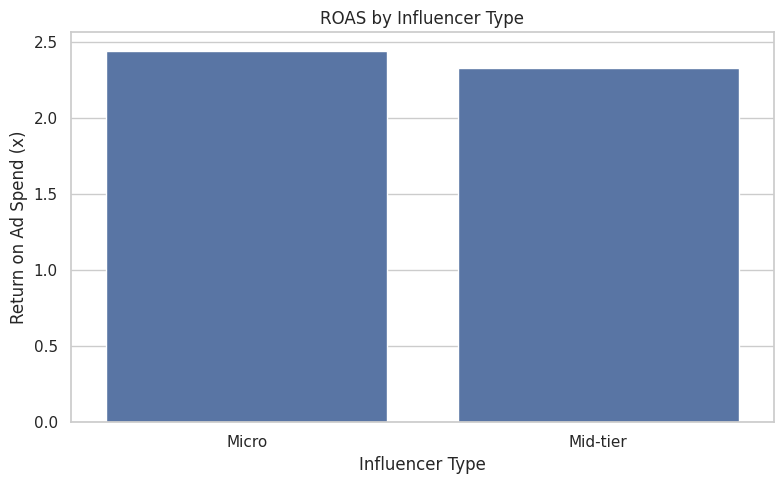

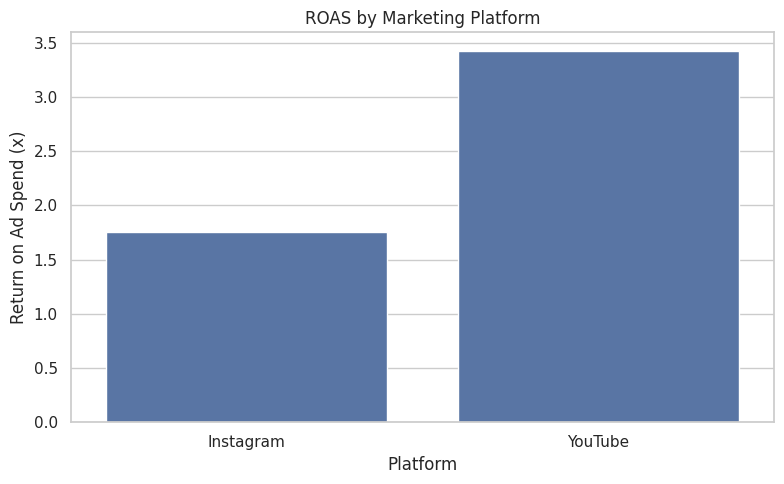

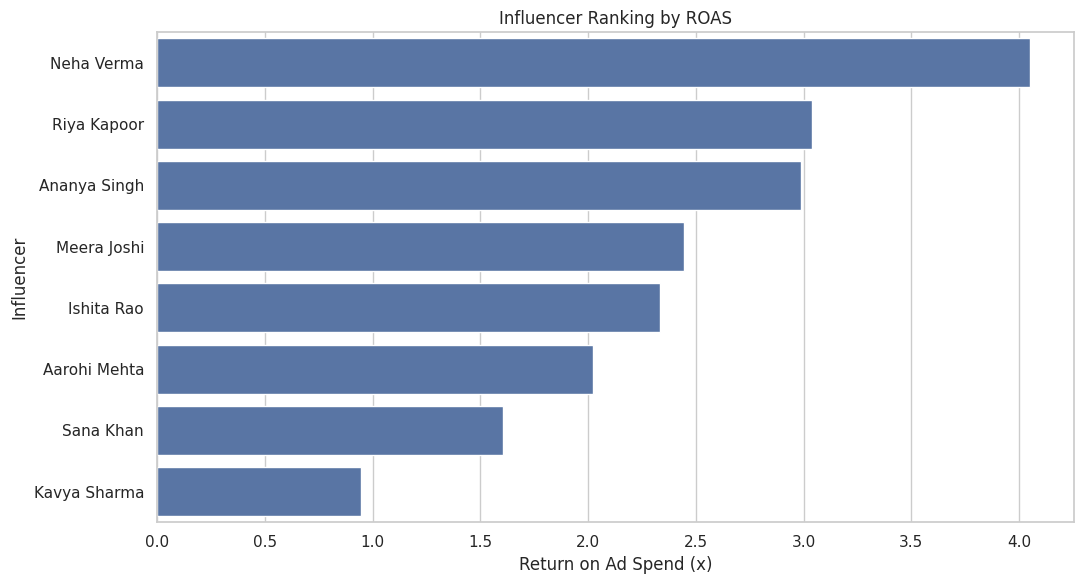

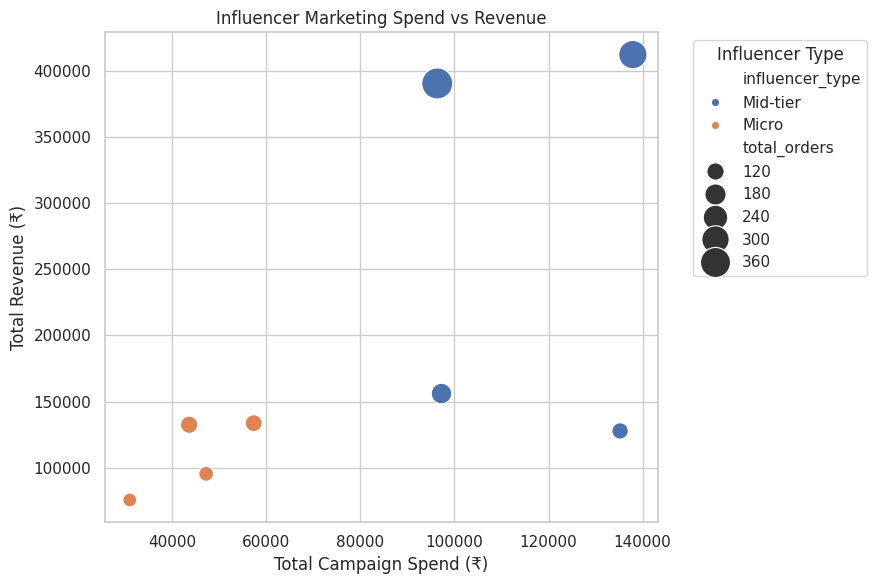

In [73]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# ==========================================
# 1. ROAS BY INFLUENCER TYPE
# ==========================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=type_analysis,
    x='influencer_type',
    y='ROAS'
)

plt.title('ROAS by Influencer Type')
plt.xlabel('Influencer Type')
plt.ylabel('Return on Ad Spend (x)')

plt.tight_layout()
plt.show()


# ==========================================
# 2. ROAS BY PLATFORM
# ==========================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=platform_analysis,
    x='platform',
    y='ROAS'
)

plt.title('ROAS by Marketing Platform')
plt.xlabel('Platform')
plt.ylabel('Return on Ad Spend (x)')

plt.tight_layout()
plt.show()


# ==========================================
# 3. INFLUENCER-WISE ROAS RANKING
# ==========================================

influencer_sorted = influencer_analysis.sort_values(
    by='ROAS',
    ascending=False
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=influencer_sorted,
    x='ROAS',
    y='influencer_name'
)

plt.title('Influencer Ranking by ROAS')
plt.xlabel('Return on Ad Spend (x)')
plt.ylabel('Influencer')

plt.tight_layout()
plt.show()


# ==========================================
# 4. SPEND VS REVENUE
# ==========================================

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=influencer_analysis,
    x='total_spend',
    y='total_revenue',
    hue='influencer_type',
    size='total_orders',
    sizes=(100, 500)
)

plt.title('Influencer Marketing Spend vs Revenue')
plt.xlabel('Total Campaign Spend (₹)')
plt.ylabel('Total Revenue (₹)')

plt.legend(
    title='Influencer Type',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()


In [77]:
influencer_df = influencer_campaigns.copy()

print(influencer_df.shape)
print(influencer_df.columns.tolist())

(8, 21)
['influencer_id', 'campaign_id', 'influencer_name', 'influencer_type', 'platform', 'followers', 'campaign_date', 'spend', 'reach', 'impressions', 'engagements', 'link_clicks', 'orders', 'revenue', 'engagement_rate', 'CTR', 'conversion_rate', 'ROAS', 'cost_per_order', 'CPM', 'revenue_per_order']


In [79]:
# Campaign Level Performance Analysis

influencer_campaign_analysis = influencer_campaigns.groupby(
    ['campaign_id', 'influencer_name', 'influencer_type', 'platform']
).agg(
    total_spend=('spend', 'sum'),
    total_reach=('reach', 'sum'),
    total_impressions=('impressions', 'sum'),
    total_engagements=('engagements', 'sum'),
    total_clicks=('link_clicks', 'sum'),
    total_orders=('orders', 'sum'),
    total_revenue=('revenue', 'sum')
).reset_index()

# Calculate performance metrics
influencer_campaign_analysis['engagement_rate'] = (
    influencer_campaign_analysis['total_engagements'] /
    influencer_campaign_analysis['total_reach'] * 100
).round(2)

influencer_campaign_analysis['CTR'] = (
    influencer_campaign_analysis['total_clicks'] /
    influencer_campaign_analysis['total_impressions'] * 100
).round(2)

influencer_campaign_analysis['conversion_rate'] = (
    influencer_campaign_analysis['total_orders'] /
    influencer_campaign_analysis['total_clicks'] * 100
).round(2)

influencer_campaign_analysis['ROAS'] = (
    influencer_campaign_analysis['total_revenue'] /
    influencer_campaign_analysis['total_spend']
).round(2)

influencer_campaign_analysis['cost_per_order'] = (
    influencer_campaign_analysis['total_spend'] /
    influencer_campaign_analysis['total_orders']
).round(2)

# Sort by revenue
influencer_campaign_analysis = influencer_campaign_analysis.sort_values(
    by='total_revenue',
    ascending=False
)

display(influencer_campaign_analysis)

,campaign_id,influencer_name,influencer_type,platform,total_spend,total_reach,total_impressions,total_engagements,total_clicks,total_orders,total_revenue,engagement_rate,CTR,conversion_rate,ROAS,cost_per_order
5,INF-C06,Ananya Singh,Mid-tier,YouTube,"137,921.02",144948,187139,7025,2679,320,"412,240.05",4.85,1.43,11.94,2.99,431.00
3,INF-C04,Neha Verma,Mid-tier,YouTube,"96,337.87",102914,131312,3815,2093,384,"390,425.70",3.71,1.59,18.35,4.05,250.88
7,INF-C08,Sana Khan,Mid-tier,Instagram,"97,240.24",54448,67816,3098,1028,168,"156,121.54",5.69,1.52,16.34,1.61,578.81
4,INF-C05,Ishita Rao,Micro,Instagram,"57,318.99",22057,36318,1667,593,115,"133,752.90",7.56,1.63,19.39,2.33,498.43
1,INF-C02,Riya Kapoor,Micro,Instagram,"43,594.06",43787,67340,2908,567,120,"132,562.45",6.64,0.84,21.16,3.04,363.28
2,INF-C03,Kavya Sharma,Mid-tier,Instagram,"135,211.94",52054,73337,4256,1132,108,"127,870.83",8.18,1.54,9.54,0.95,"1,251.96"
0,INF-C01,Aarohi Mehta,Micro,Instagram,"47,209.08",25881,41693,1653,407,88,"95,477.74",6.39,0.98,21.62,2.02,536.47
6,INF-C07,Meera Joshi,Micro,Instagram,"30,969.14",21019,24629,1316,479,77,"75,714.91",6.26,1.94,16.08,2.44,402.20


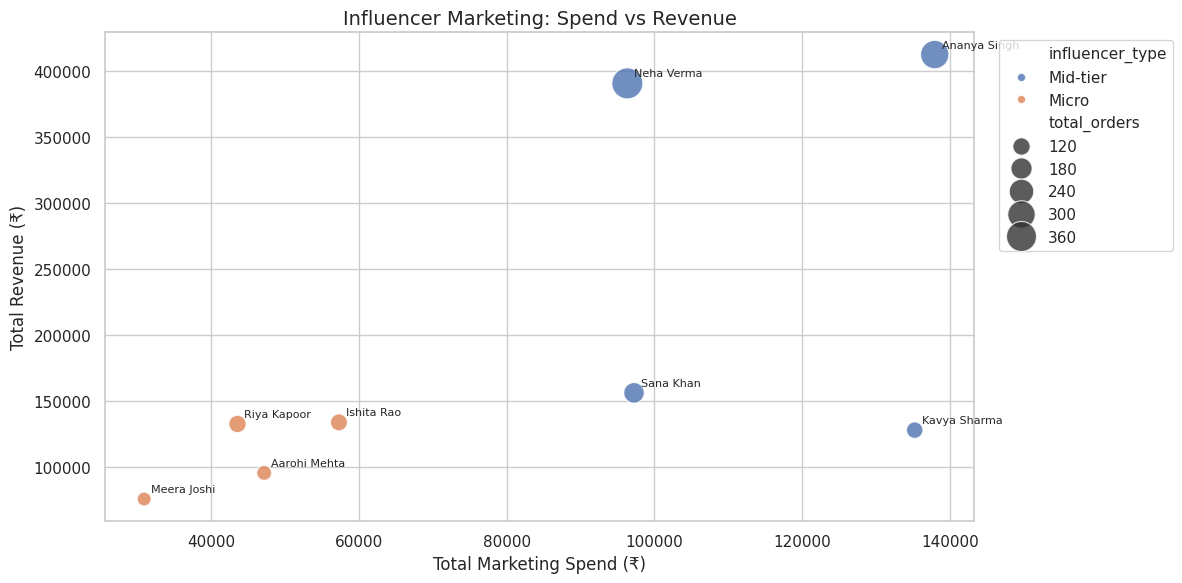

In [80]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=influencer_campaign_analysis,
    x='total_spend',
    y='total_revenue',
    hue='influencer_type',
    size='total_orders',
    sizes=(100, 500),
    alpha=0.8
)

for _, row in influencer_campaign_analysis.iterrows():
    plt.annotate(
        row['influencer_name'],
        (row['total_spend'], row['total_revenue']),
        fontsize=8,
        xytext=(5, 5),
        textcoords='offset points'
    )

plt.title('Influencer Marketing: Spend vs Revenue', fontsize=14)
plt.xlabel('Total Marketing Spend (₹)')
plt.ylabel('Total Revenue (₹)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

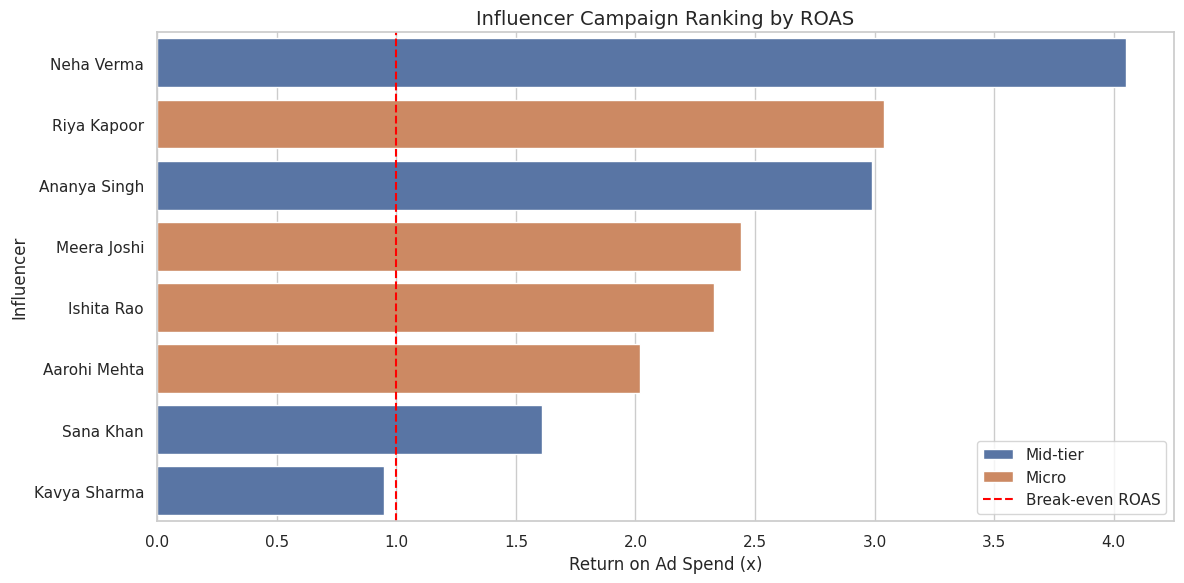

In [81]:
roas_data = influencer_campaign_analysis.sort_values(
    by='ROAS',
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=roas_data,
    x='ROAS',
    y='influencer_name',
    hue='influencer_type',
    dodge=False
)

plt.title('Influencer Campaign Ranking by ROAS', fontsize=14)
plt.xlabel('Return on Ad Spend (x)')
plt.ylabel('Influencer')
plt.axvline(
    x=1,
    color='red',
    linestyle='--',
    label='Break-even ROAS'
)

plt.legend()
plt.tight_layout()
plt.show()

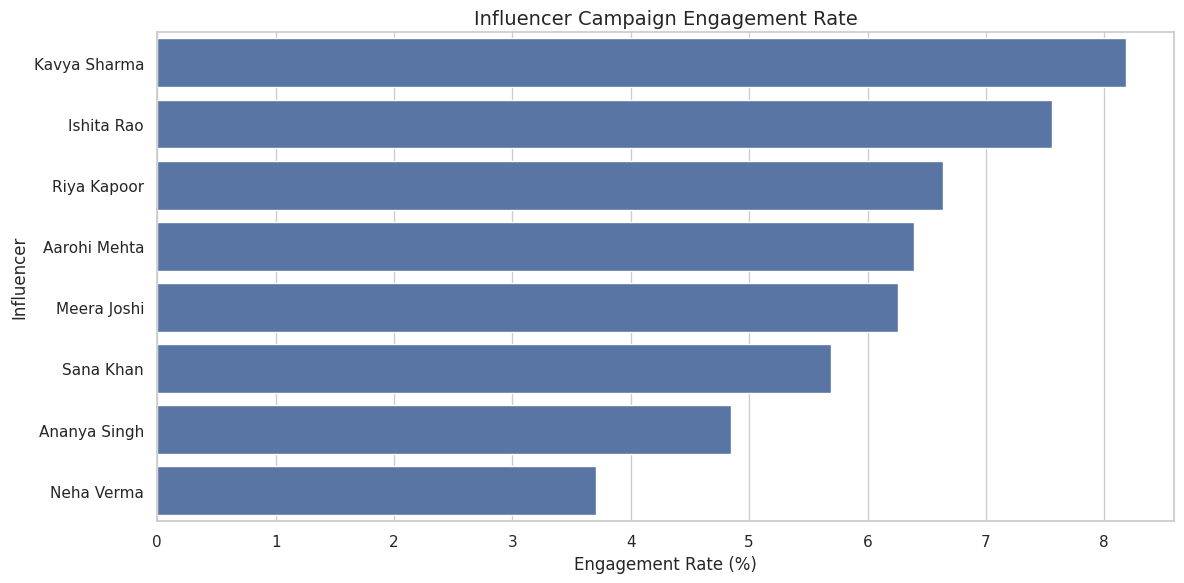

In [82]:
engagement_data = influencer_campaign_analysis.sort_values(
    by='engagement_rate',
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=engagement_data,
    x='engagement_rate',
    y='influencer_name'
)

plt.title('Influencer Campaign Engagement Rate', fontsize=14)
plt.xlabel('Engagement Rate (%)')
plt.ylabel('Influencer')

plt.tight_layout()
plt.show()

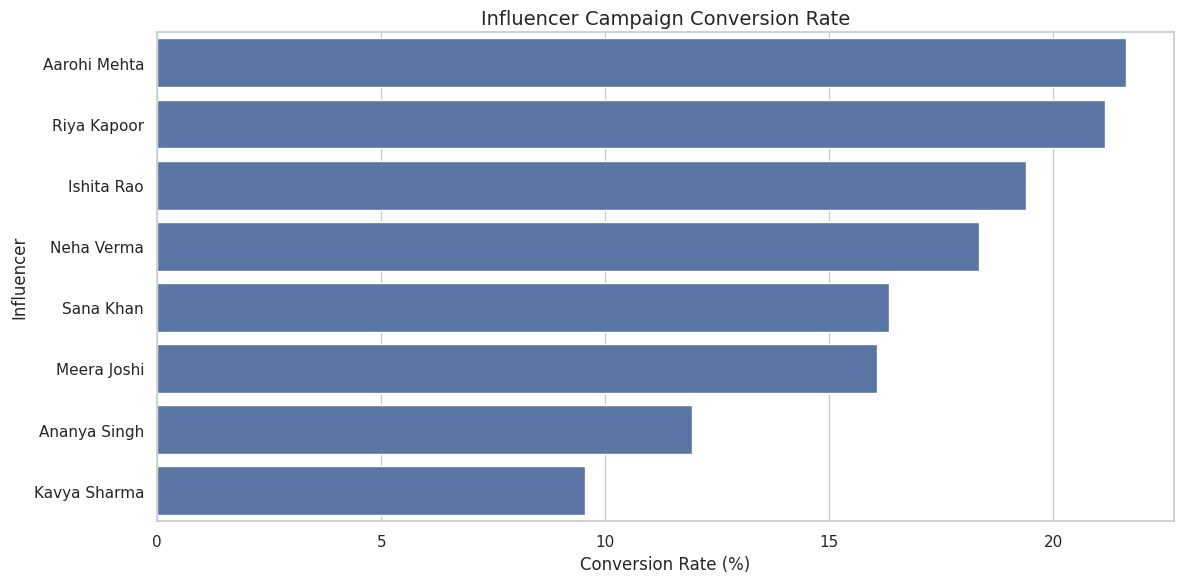

In [83]:
conversion_data = influencer_campaign_analysis.sort_values(
    by='conversion_rate',
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=conversion_data,
    x='conversion_rate',
    y='influencer_name'
)

plt.title('Influencer Campaign Conversion Rate', fontsize=14)
plt.xlabel('Conversion Rate (%)')
plt.ylabel('Influencer')

plt.tight_layout()
plt.show()

In [84]:
best_roas = influencer_campaign_analysis.loc[
    influencer_campaign_analysis['ROAS'].idxmax()
]

best_revenue = influencer_campaign_analysis.loc[
    influencer_campaign_analysis['total_revenue'].idxmax()
]

best_engagement = influencer_campaign_analysis.loc[
    influencer_campaign_analysis['engagement_rate'].idxmax()
]

best_conversion = influencer_campaign_analysis.loc[
    influencer_campaign_analysis['conversion_rate'].idxmax()
]

print("INFLUENCER MARKETING BUSINESS INSIGHTS")
print("-" * 45)

print(f"Highest ROAS: {best_roas['influencer_name']}")
print(f"ROAS: {best_roas['ROAS']}x")

print(f"\nHighest Revenue: {best_revenue['influencer_name']}")
print(f"Revenue: ₹{best_revenue['total_revenue']:,.2f}")

print(f"\nHighest Engagement: {best_engagement['influencer_name']}")
print(f"Engagement Rate: {best_engagement['engagement_rate']}%")

print(f"\nHighest Conversion: {best_conversion['influencer_name']}")
print(f"Conversion Rate: {best_conversion['conversion_rate']}%")

INFLUENCER MARKETING BUSINESS INSIGHTS
---------------------------------------------
Highest ROAS: Neha Verma
ROAS: 4.05x

Highest Revenue: Ananya Singh
Revenue: ₹412,240.05

Highest Engagement: Kavya Sharma
Engagement Rate: 8.18%

Highest Conversion: Aarohi Mehta
Conversion Rate: 21.62%


In [85]:
# Overall Influencer Marketing KPIs

total_investment = influencer_campaigns['spend'].sum()
total_revenue = influencer_campaigns['revenue'].sum()
total_orders = influencer_campaigns['orders'].sum()
total_campaigns = influencer_campaigns['campaign_id'].nunique()

overall_roas = total_revenue / total_investment

print("INFLUENCER MARKETING KPI SUMMARY")
print("-" * 40)
print(f"Total Campaigns: {total_campaigns}")
print(f"Total Investment: ₹{total_investment:,.2f}")
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Overall ROAS: {overall_roas:.2f}x")

INFLUENCER MARKETING KPI SUMMARY
----------------------------------------
Total Campaigns: 8
Total Investment: ₹645,802.34
Total Revenue: ₹1,524,166.12
Total Orders: 1,380
Overall ROAS: 2.36x


In [86]:
# Influencer Type Comparison

type_comparison = influencer_campaigns.groupby(
    'influencer_type'
).agg(
    total_spend=('spend', 'sum'),
    total_revenue=('revenue', 'sum'),
    total_orders=('orders', 'sum')
).reset_index()

type_comparison['ROAS'] = (
    type_comparison['total_revenue'] /
    type_comparison['total_spend']
).round(2)


# Platform Comparison

platform_comparison = influencer_campaigns.groupby(
    'platform'
).agg(
    total_spend=('spend', 'sum'),
    total_revenue=('revenue', 'sum'),
    total_orders=('orders', 'sum')
).reset_index()

platform_comparison['ROAS'] = (
    platform_comparison['total_revenue'] /
    platform_comparison['total_spend']
).round(2)

display(type_comparison)
display(platform_comparison)

,influencer_type,total_spend,total_revenue,total_orders,ROAS
0,Micro,"179,091.27","437,508.00",400,2.44
1,Mid-tier,"466,711.07","1,086,658.12",980,2.33


,platform,total_spend,total_revenue,total_orders,ROAS
0,Instagram,"411,543.45","721,500.37",676,1.75
1,YouTube,"234,258.89","802,665.75",704,3.43


/tmp/ipykernel_779/2161761696.py:94: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.95])


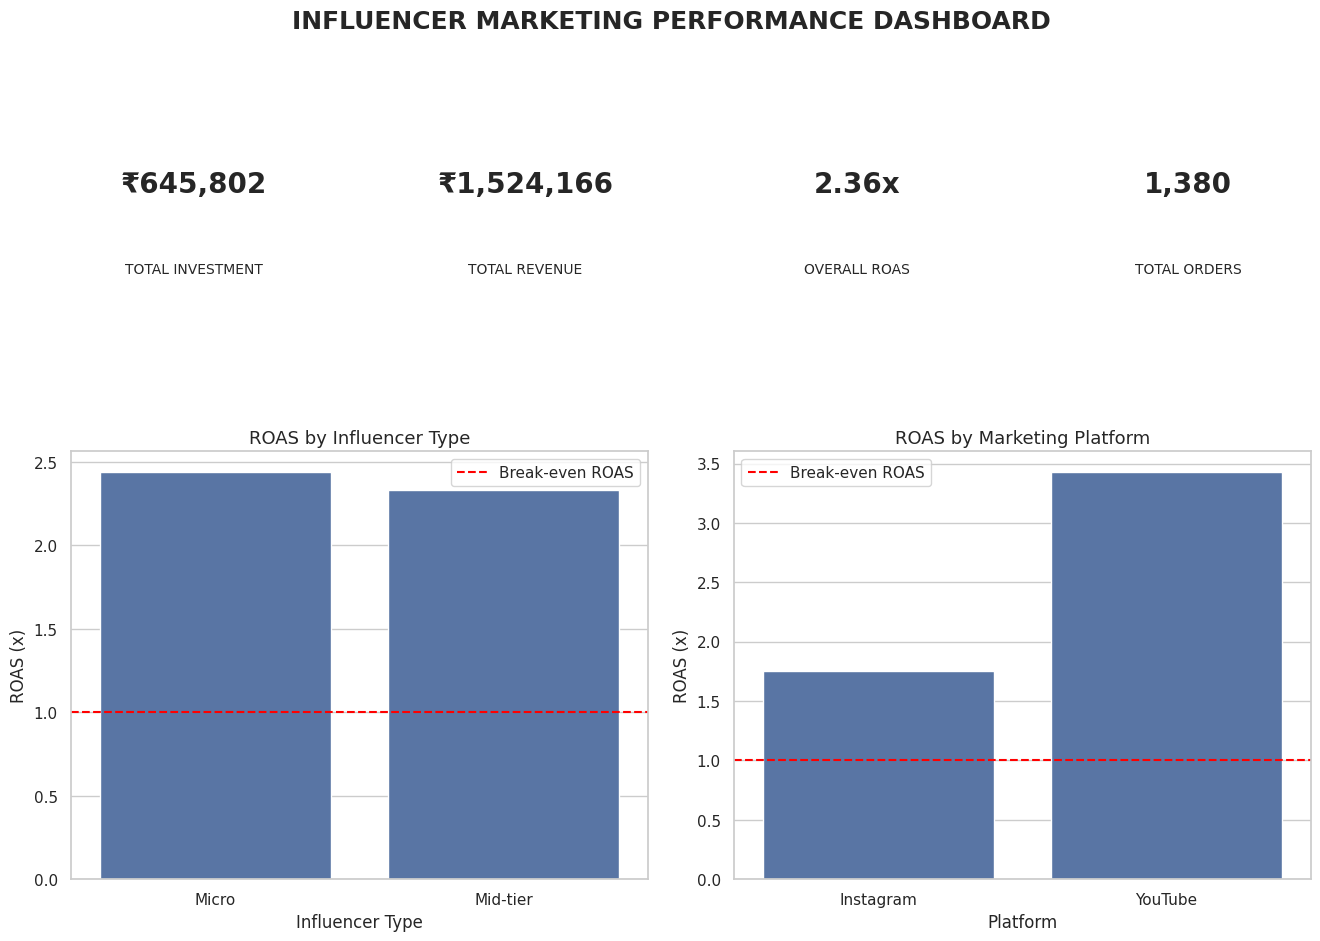

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig = plt.figure(figsize=(16, 10))

gs = fig.add_gridspec(
    2, 4,
    height_ratios=[1, 2],
    hspace=0.4,
    wspace=0.35
)

# Dashboard title
fig.suptitle(
    'INFLUENCER MARKETING PERFORMANCE DASHBOARD',
    fontsize=18,
    fontweight='bold',
    y=0.98
)

# KPI Cards
kpis = [
    ('TOTAL INVESTMENT', f'₹{total_investment:,.0f}'),
    ('TOTAL REVENUE', f'₹{total_revenue:,.0f}'),
    ('OVERALL ROAS', f'{overall_roas:.2f}x'),
    ('TOTAL ORDERS', f'{total_orders:,}')
]

for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i])
    ax.axis('off')

    ax.text(
        0.5, 0.65, value,
        ha='center',
        va='center',
        fontsize=20,
        fontweight='bold'
    )

    ax.text(
        0.5, 0.25, label,
        ha='center',
        va='center',
        fontsize=10
    )

# ROAS by Influencer Type
ax1 = fig.add_subplot(gs[1, :2])

sns.barplot(
    data=type_comparison,
    x='influencer_type',
    y='ROAS',
    ax=ax1
)

ax1.axhline(
    1,
    color='red',
    linestyle='--',
    label='Break-even ROAS'
)

ax1.set_title('ROAS by Influencer Type', fontsize=13)
ax1.set_xlabel('Influencer Type')
ax1.set_ylabel('ROAS (x)')
ax1.legend()

# ROAS by Platform
ax2 = fig.add_subplot(gs[1, 2:])

sns.barplot(
    data=platform_comparison,
    x='platform',
    y='ROAS',
    ax=ax2
)

ax2.axhline(
    1,
    color='red',
    linestyle='--',
    label='Break-even ROAS'
)

ax2.set_title('ROAS by Marketing Platform', fontsize=13)
ax2.set_xlabel('Platform')
ax2.set_ylabel('ROAS (x)')
ax2.legend()

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [88]:
best_type = type_comparison.loc[
    type_comparison['ROAS'].idxmax()
]

best_platform = platform_comparison.loc[
    platform_comparison['ROAS'].idxmax()
]

print("\nEXECUTIVE SUMMARY")
print("=" * 50)

print(f"Total Marketing Investment: ₹{total_investment:,.2f}")
print(f"Total Revenue Generated: ₹{total_revenue:,.2f}")
print(f"Total Orders Generated: {total_orders:,}")
print(f"Overall ROAS: {overall_roas:.2f}x")

print("\nKEY FINDINGS")
print("-" * 50)

print(
    f"Best Influencer Type: {best_type['influencer_type']} "
    f"({best_type['ROAS']:.2f}x ROAS)"
)

print(
    f"Best Marketing Platform: {best_platform['platform']} "
    f"({best_platform['ROAS']:.2f}x ROAS)"
)

print("\nRECOMMENDATIONS")
print("-" * 50)

print("1. Prioritize influencer categories with higher ROAS.")
print("2. Allocate more budget to better-performing platforms.")
print("3. Optimize campaigns with ROAS below 1.")
print("4. Monitor revenue, conversion rate and cost per order.")
print("5. Test budget allocation before scaling campaigns.")


EXECUTIVE SUMMARY
Total Marketing Investment: ₹645,802.34
Total Revenue Generated: ₹1,524,166.12
Total Orders Generated: 1,380
Overall ROAS: 2.36x

KEY FINDINGS
--------------------------------------------------
Best Influencer Type: Micro (2.44x ROAS)
Best Marketing Platform: YouTube (3.43x ROAS)

RECOMMENDATIONS
--------------------------------------------------
1. Prioritize influencer categories with higher ROAS.
2. Allocate more budget to better-performing platforms.
3. Optimize campaigns with ROAS below 1.
4. Monitor revenue, conversion rate and cost per order.
5. Test budget allocation before scaling campaigns.
